In [64]:
!pip -q install kagglehub opencv-python-headless scikit-image scipy pandas matplotlib


In [65]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from pathlib import Path
from scipy.fft import dctn
from scipy.linalg import hadamard
from collections import deque
from tqdm.auto import tqdm

print("All imports completed successfully!")
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

All imports completed successfully!
OpenCV version: 5.0.0
NumPy version: 2.1.3


In [66]:
import kagglehub
import os

# Download the Brain Tumor MRI Dataset
dataset_path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)
print("\nFiles and folders:")

print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/brain-tumor-mri-dataset

Files and folders:
['Training', 'Testing']


In [67]:
from pathlib import Path

ROOT = Path(dataset_path)

print("Main folder:", ROOT)

for item in ROOT.iterdir():
    print(item.name)

Main folder: /kaggle/input/brain-tumor-mri-dataset
Training
Testing


In [68]:
from pathlib import Path

# Dataset folders
ROOT = Path(dataset_path)
TRAIN_DIR = ROOT / "Training"
TEST_DIR = ROOT / "Testing"

# MRI dataset categories
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# Supported image formats
VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

# Count images in each category
for folder_name, folder_path in [
    ("TRAINING", TRAIN_DIR),
    ("TESTING", TEST_DIR)
]:
    print(f"\n{'=' * 35}")
    print(folder_name)
    print("=" * 35)

    total = 0

    for class_name in CLASSES:
        class_folder = folder_path / class_name

        if not class_folder.exists():
            print(f"{class_name}: Folder not found!")
            continue

        images = [
            file for file in class_folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in VALID_EXTENSIONS
        ]

        print(f"{class_name}: {len(images)} images")
        total += len(images)

    print("Total images:", total)


TRAINING
glioma: 1400 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images
Total images: 5600

TESTING
glioma: 400 images
meningioma: 400 images
notumor: 400 images
pituitary: 400 images
Total images: 1600


Image name: Tr-gl_1260.jpg
Image dimensions: (512, 512)
Minimum pixel intensity: 0
Maximum pixel intensity: 252
Pixel data type: uint8


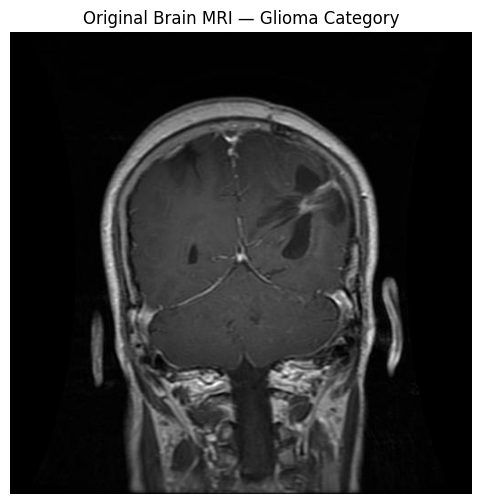

In [69]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# Select one MRI image from the training dataset
sample_folder = TRAIN_DIR / "glioma"

sample_images = [
    p for p in sample_folder.iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
]

sample_path = random.choice(sample_images)

# Read the image in grayscale
image = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Could not load the MRI image.")

# Display image properties
print("Image name:", sample_path.name)
print("Image dimensions:", image.shape)
print("Minimum pixel intensity:", image.min())
print("Maximum pixel intensity:", image.max())
print("Pixel data type:", image.dtype)

# Display the MRI
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original Brain MRI — Glioma Category")
plt.axis("off")
plt.show()

Original image dimensions: (512, 512)
Resized image dimensions: (256, 256)


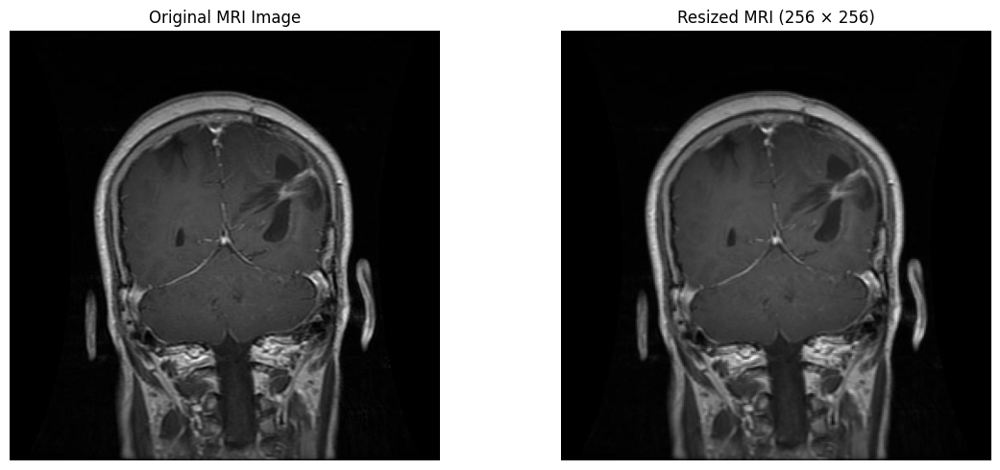

In [70]:
# Resize the original MRI image
IMG_SIZE = (256, 256)

resized_image = cv2.resize(
    image,
    IMG_SIZE,
    interpolation=cv2.INTER_AREA
)

# Display dimensions
print("Original image dimensions:", image.shape)
print("Resized image dimensions:", resized_image.shape)

# Compare original and resized images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image, cmap="gray")
plt.title("Resized MRI (256 × 256)")
plt.axis("off")

plt.tight_layout()
plt.show()

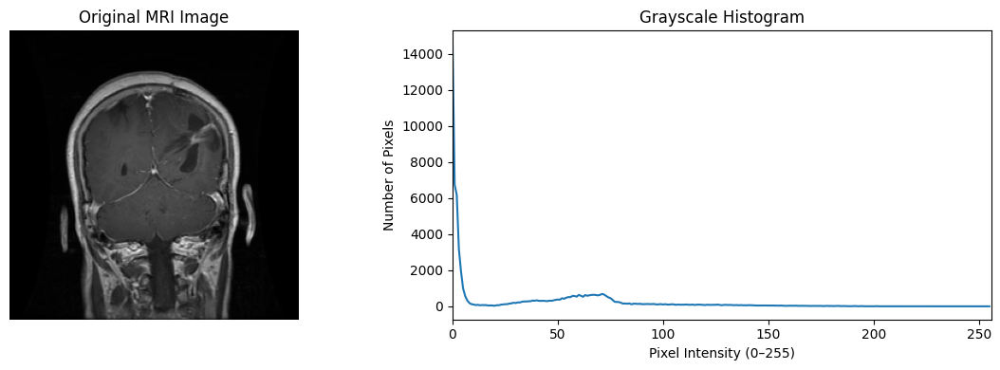

In [71]:
# Calculate the grayscale histogram
histogram = cv2.calcHist(
    [resized_image],
    [0],
    None,
    [256],
    [0, 256]
)

# Display the MRI image and its histogram
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.plot(histogram)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

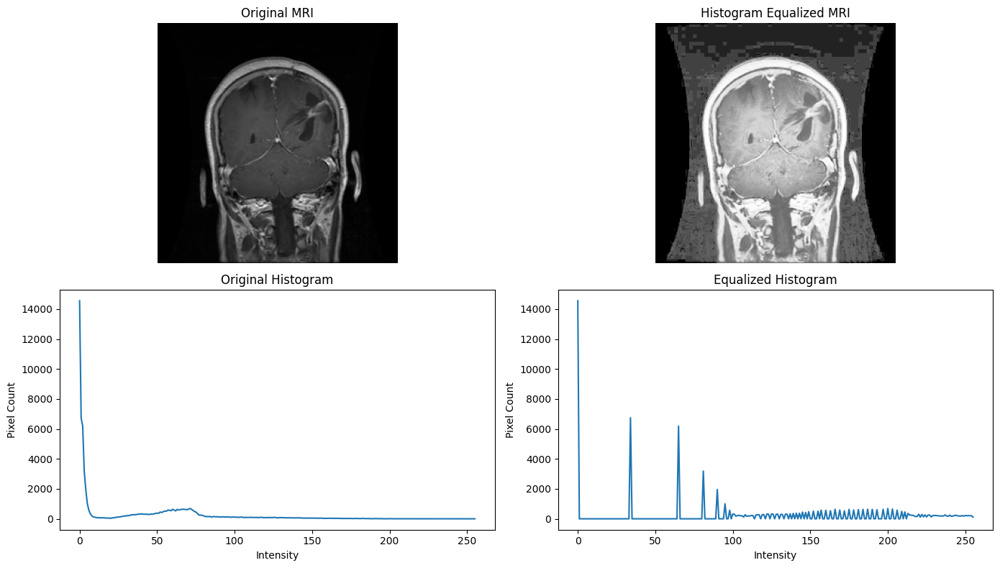

In [72]:
# Apply histogram equalization
equalized_image = cv2.equalizeHist(resized_image)

# Calculate the new histogram
equalized_histogram = cv2.calcHist(
    [equalized_image],
    [0],
    None,
    [256],
    [0, 256]
)

# Compare original and equalized images
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized MRI")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.plot(histogram)
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Pixel Count")

plt.subplot(2, 2, 4)
plt.plot(equalized_histogram)
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Pixel Count")

plt.tight_layout()
plt.show()

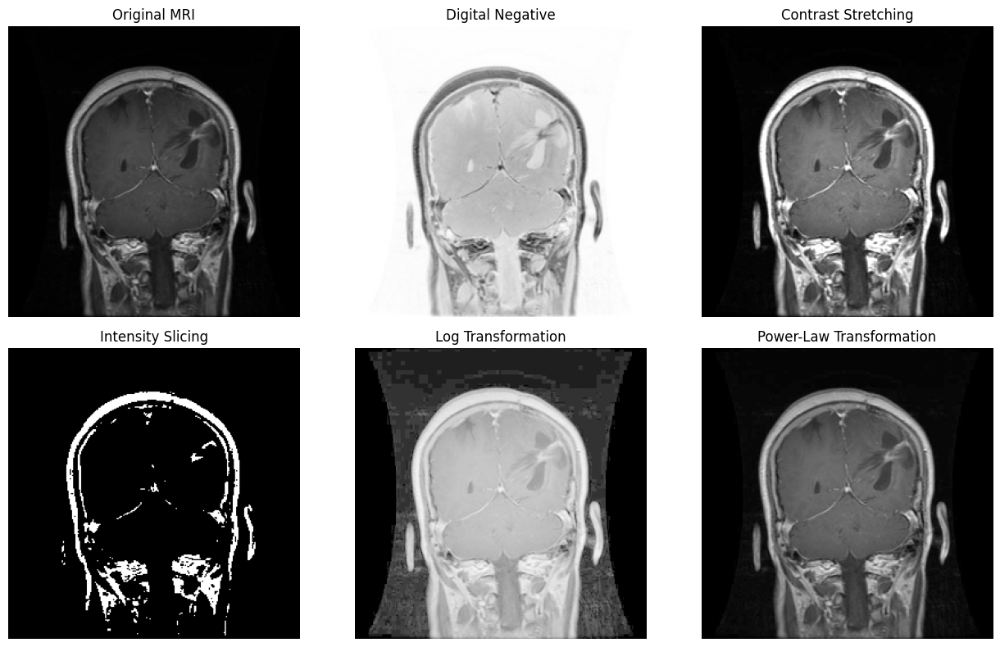

In [73]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Use the resized MRI image from Step 5
img = resized_image

# 1. Digital Negative
negative = 255 - img

# 2. Contrast Stretching
img_float = img.astype(np.float32)

p2, p98 = np.percentile(img_float, (2, 98))

stretched = np.clip(
    (img_float - p2) * 255 / max(p98 - p2, 1),
    0, 255
).astype(np.uint8)

# 3. Intensity-Level Slicing
sliced = np.zeros_like(img)
sliced[(img >= 100) & (img <= 200)] = 255

# 4. Logarithmic Transformation
log_image = (
    255 * np.log1p(img_float) / np.log1p(255)
).astype(np.uint8)

# 5. Power-Law (Gamma) Transformation
gamma = 0.7

power_image = (
    255 * (img_float / 255.0) ** gamma
).astype(np.uint8)

# Display all results
results = [
    (img, "Original MRI"),
    (negative, "Digital Negative"),
    (stretched, "Contrast Stretching"),
    (sliced, "Intensity Slicing"),
    (log_image, "Log Transformation"),
    (power_image, "Power-Law Transformation")
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, (result, title) in zip(axes.ravel(), results):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

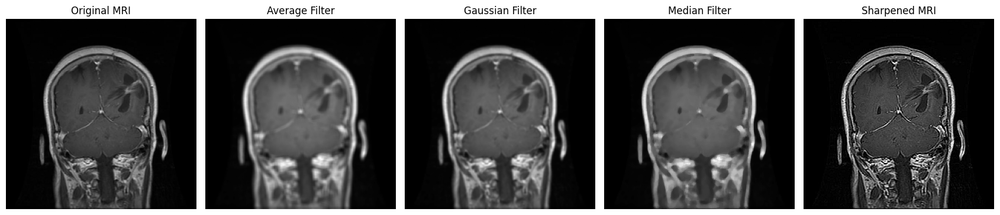

In [74]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the resized MRI image from Step 5
img = resized_image

# 1. Average filter
average_filtered = cv2.blur(img, (5, 5))

# 2. Gaussian filter
gaussian_filtered = cv2.GaussianBlur(
    img, (5, 5), sigmaX=1.0
)

# 3. Median filter
median_filtered = cv2.medianBlur(img, 5)

# 4. Sharpening filter
sharpening_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

sharpened_image = cv2.filter2D(
    img, -1, sharpening_kernel
)

# Display the results
results = [
    (img, "Original MRI"),
    (average_filtered, "Average Filter"),
    (gaussian_filtered, "Gaussian Filter"),
    (median_filtered, "Median Filter"),
    (sharpened_image, "Sharpened MRI")
]

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, (result, title) in zip(axes, results):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

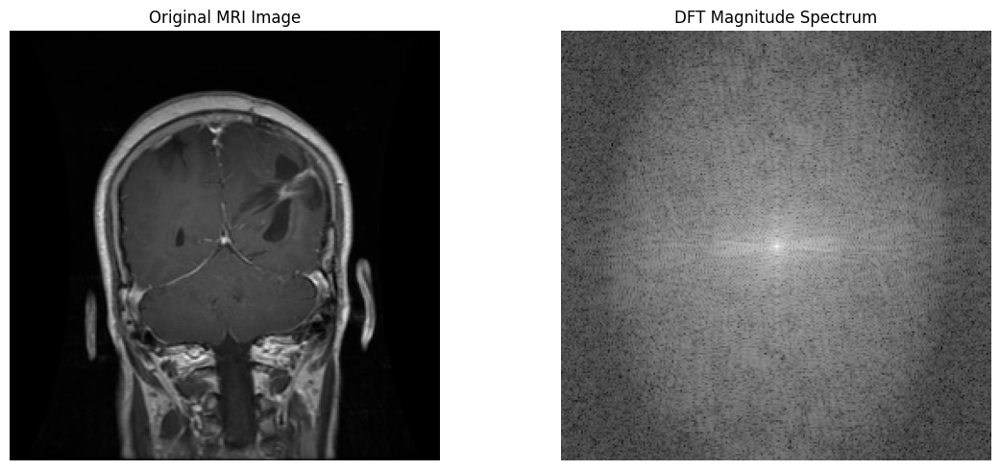

In [75]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the resized MRI image from Step 5
img = resized_image.astype(np.float32)

# Calculate 2D Discrete Fourier Transform
dft = cv2.dft(
    img,
    flags=cv2.DFT_COMPLEX_OUTPUT
)

# Shift zero frequency to the center
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

# Calculate magnitude spectrum
magnitude = cv2.magnitude(
    dft_shift[:, :, 0],
    dft_shift[:, :, 1]
)

# Log scaling for visualization
spectrum = 20 * np.log(magnitude + 1)

# Display original image and spectrum
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(spectrum, cmap="gray")
plt.title("DFT Magnitude Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()

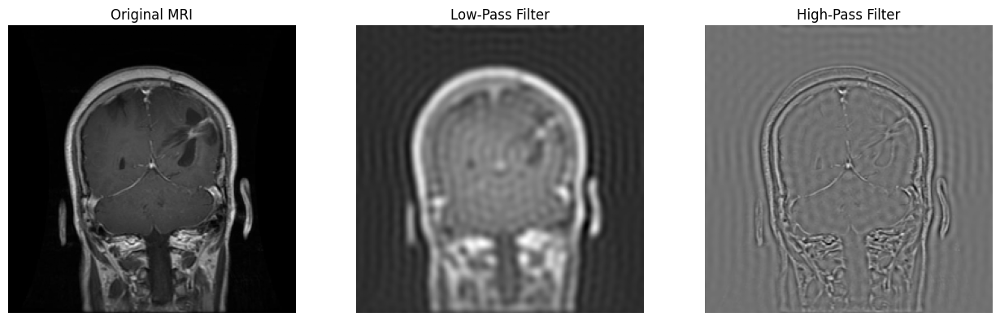

In [76]:
# Get image dimensions
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

# Create distance map from the center
Y, X = np.ogrid[:rows, :cols]
distance = np.sqrt(
    (Y - crow)**2 + (X - ccol)**2
)

# Define cutoff radius
radius = 25

# Create frequency masks
low_mask = (distance <= radius).astype(np.float32)
high_mask = 1.0 - low_mask

# Apply masks to the shifted DFT
low_dft = dft_shift * low_mask[:, :, None]
high_dft = dft_shift * high_mask[:, :, None]

# Inverse DFT to reconstruct images
low_filtered = cv2.idft(
    np.fft.ifftshift(low_dft, axes=(0, 1)),
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

high_filtered = cv2.idft(
    np.fft.ifftshift(high_dft, axes=(0, 1)),
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(resized_image, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(low_filtered, cmap="gray")
axes[1].set_title("Low-Pass Filter")

axes[2].imshow(high_filtered, cmap="gray")
axes[2].set_title("High-Pass Filter")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

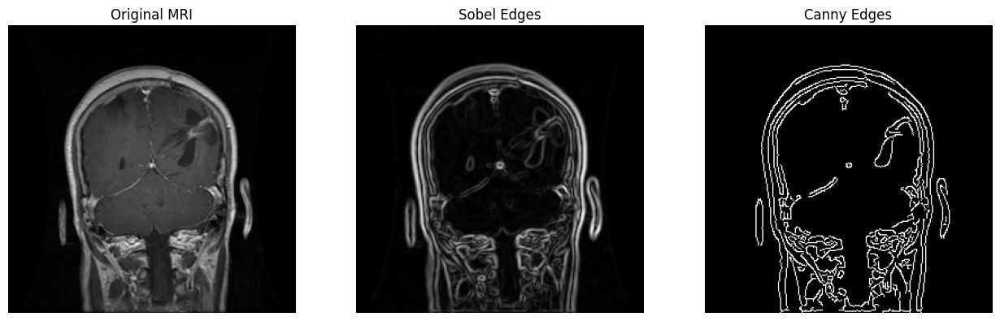

In [77]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the resized MRI image from Step 5
img = resized_image

# Apply Gaussian smoothing before edge detection
# This reduces noise that may create false edges.
smoothed = cv2.GaussianBlur(img, (5, 5), 1.0)

# 1. Sobel edge detection
sobel_x = cv2.Sobel(
    smoothed, cv2.CV_32F, 1, 0, ksize=3
)

sobel_y = cv2.Sobel(
    smoothed, cv2.CV_32F, 0, 1, ksize=3
)

sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)

# Normalize for visualization
sobel_edges = cv2.normalize(
    sobel_magnitude,
    None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# 2. Canny edge detection
canny_edges = cv2.Canny(
    smoothed,
    threshold1=50,
    threshold2=150
)

# Compare outputs
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(sobel_edges, cmap="gray")
axes[1].set_title("Sobel Edges")

axes[2].imshow(canny_edges, cmap="gray")
axes[2].set_title("Canny Edges")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Otsu threshold selected: 39.0


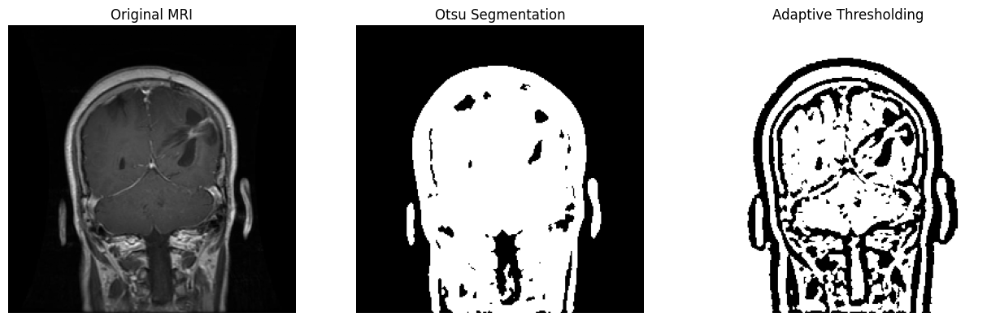

In [78]:
import cv2
import matplotlib.pyplot as plt

# Use the existing MRI image
img = resized_image

# Apply Gaussian smoothing before segmentation
smoothed = cv2.GaussianBlur(img, (5, 5), 1.0)

# 1. Otsu thresholding
otsu_threshold, otsu_mask = cv2.threshold(
    smoothed,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 2. Adaptive thresholding
adaptive_mask = cv2.adaptiveThreshold(
    smoothed,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    3
)

print("Otsu threshold selected:", otsu_threshold)

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(otsu_mask, cmap="gray")
axes[1].set_title("Otsu Segmentation")

axes[2].imshow(adaptive_mask, cmap="gray")
axes[2].set_title("Adaptive Thresholding")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

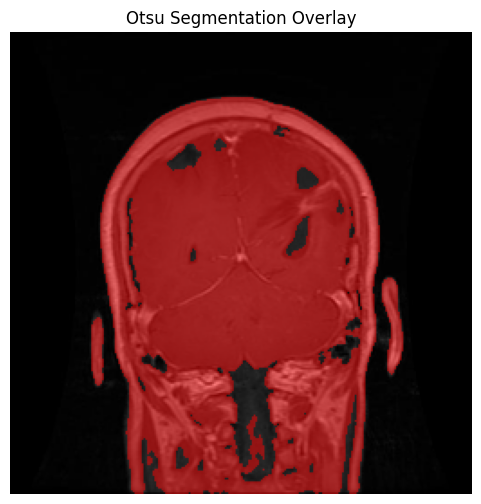

In [79]:
# Convert grayscale MRI into RGB
overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

# Create a red color array
red = np.array([255, 0, 0], dtype=np.float32)

# Select segmented pixels
mask = otsu_mask == 255

# Blend original pixels with red
overlay[mask] = (
    0.5 * overlay[mask].astype(np.float32)
    + 0.5 * red
).astype(np.uint8)

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(overlay)
plt.title("Otsu Segmentation Overlay")
plt.axis("off")
plt.show()

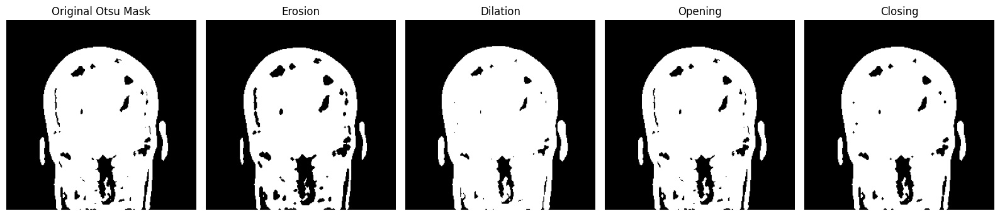

In [80]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the Otsu mask from Step 11
mask = otsu_mask.copy()

# Create a small elliptical structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

# Morphological operations
eroded = cv2.erode(mask, kernel, iterations=1)

dilated = cv2.dilate(mask, kernel, iterations=1)

opened = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel
)

closed = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel
)

# Display comparison
results = [
    (mask, "Original Otsu Mask"),
    (eroded, "Erosion"),
    (dilated, "Dilation"),
    (opened, "Opening"),
    (closed, "Closing")
]

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (result, title) in zip(axes, results):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Total foreground components: 5


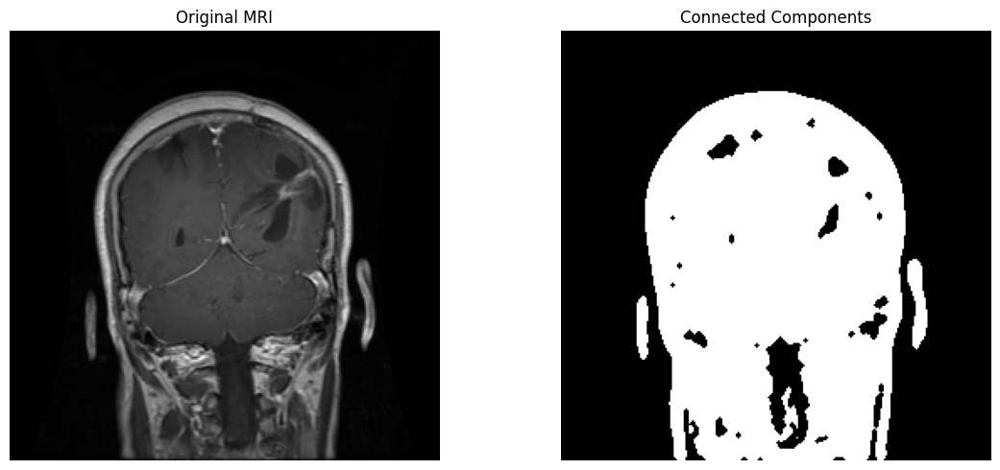

In [81]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the cleaned mask from Step 12
mask = closed.copy()

# Find connected components
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )
)

print("Total foreground components:", num_labels - 1)

# Create an image for visualization
component_image = np.zeros_like(resized_image)

# Store component details
component_details = []

for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    cx, cy = centroids[i]

    component_details.append({
        "Component": i,
        "Area": int(area),
        "Width": int(w),
        "Height": int(h),
        "Centroid_X": round(cx, 2),
        "Centroid_Y": round(cy, 2)
    })

    # Assign a visible intensity to each component
    component_image[labels == i] = 180

# Display the connected regions
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(resized_image, cmap="gray")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(component_image, cmap="gray")
plt.title("Connected Components")
plt.axis("off")

plt.tight_layout()
plt.show()

In [82]:
import pandas as pd

components_df = pd.DataFrame(component_details)

if not components_df.empty:
    components_df = components_df.sort_values(
        by="Area",
        ascending=False
    )

    display(components_df.head(15))
else:
    print("No foreground components detected.")

,Component,Area,Width,Height,Centroid_X,Centroid_Y
0,1,27113,155,220,127.72,145.27
1,2,385,12,54,211.78,161.06
2,3,224,7,38,47.94,176.18
3,4,13,3,5,76.85,237.00
4,5,1,1,1,140.00,242.00


In [83]:
from pathlib import Path
import pandas as pd
import random

# Dataset paths from Step 3
TRAIN_DIR = Path(dataset_path) / "Training"
TEST_DIR = Path(dataset_path) / "Testing"

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

def collect_images(folder):
    records = []

    for class_name in CLASSES:
        class_folder = folder / class_name

        for path in class_folder.iterdir():
            if (
                path.is_file()
                and path.suffix.lower() in VALID_EXTENSIONS
            ):
                records.append({
                    "path": str(path),
                    "class_name": class_name,
                    "label": 0 if class_name == "notumor" else 1
                })

    return records

# Collect image paths and labels
training_images = collect_images(TRAIN_DIR)
testing_images = collect_images(TEST_DIR)

# Reproducible shuffle
random.seed(42)
random.shuffle(training_images)

# Split the original training folder:
# 80% calibration, 20% validation
split_index = int(0.8 * len(training_images))

calibration_images = training_images[:split_index]
validation_images = training_images[split_index:]

print("Calibration images:", len(calibration_images))
print("Validation images:", len(validation_images))
print("Final testing images:", len(testing_images))

print("\nExample training records:")
display(pd.DataFrame(calibration_images).head())

Calibration images: 4480
Validation images: 1120
Final testing images: 1600

Example training records:


,path,class_name,label
0,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1
1,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1
2,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1
3,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,1
4,/kaggle/input/brain-tumor-mri-dataset/Training...,notumor,0


In [84]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (256, 256)

def process_mri(image_path):
    # 1. Load MRI as grayscale
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise ValueError(f"Could not load image: {image_path}")

    # 2. Standardize image dimensions
    img = cv2.resize(
        img, IMG_SIZE,
        interpolation=cv2.INTER_AREA
    )

    # 3. Enhance local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(img)

    # 4. Reduce noise before edge detection
    smoothed = cv2.GaussianBlur(
        enhanced, (5, 5), 1.0
    )

    # 5. Detect edges
    edges = cv2.Canny(
        smoothed, 50, 150
    )

    # 6. Otsu thresholding
    otsu_threshold, mask = cv2.threshold(
        smoothed,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # 7. Clean small foreground structures and gaps
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    opened = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    cleaned = cv2.morphologyEx(
        opened, cv2.MORPH_CLOSE, kernel
    )

    # 8. Measure connected foreground regions
    num_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            cleaned, connectivity=8
        )
    )

    components = []

    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]

        components.append({
            "x": int(x),
            "y": int(y),
            "width": int(w),
            "height": int(h),
            "area": int(area),
            "centroid_x": float(centroids[i][0]),
            "centroid_y": float(centroids[i][1])
        })

    return {
        "original": img,
        "enhanced": enhanced,
        "smoothed": smoothed,
        "edges": edges,
        "otsu_mask": mask,
        "cleaned_mask": cleaned,
        "otsu_threshold": float(otsu_threshold),
        "components": components
    }

print("IVP processing function created successfully.")

IVP processing function created successfully.


Actual category: glioma
Otsu threshold: 67.0
Connected foreground regions: 1


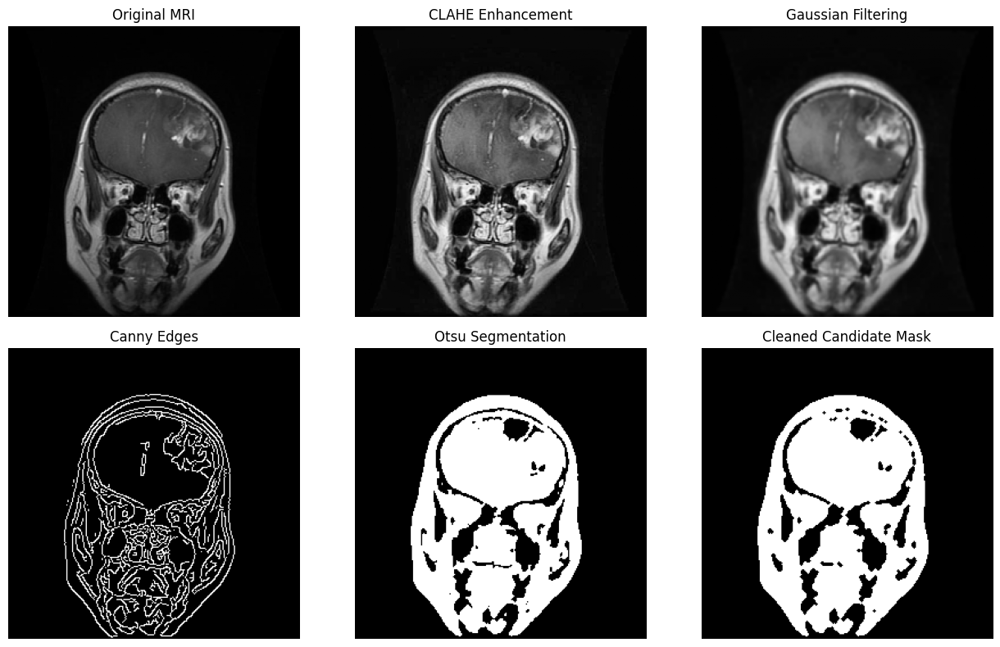

In [85]:
# Use an image from the calibration dataset
sample_record = calibration_images[0]

result = process_mri(sample_record["path"])

print("Actual category:", sample_record["class_name"])
print("Otsu threshold:", result["otsu_threshold"])
print("Connected foreground regions:", len(result["components"]))

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

images = [
    (result["original"], "Original MRI"),
    (result["enhanced"], "CLAHE Enhancement"),
    (result["smoothed"], "Gaussian Filtering"),
    (result["edges"], "Canny Edges"),
    (result["otsu_mask"], "Otsu Segmentation"),
    (result["cleaned_mask"], "Cleaned Candidate Mask")
]

for ax, (image, title) in zip(axes.ravel(), images):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Use a small sample first to check the pipeline
SAMPLE_PER_CLASS = 20

analysis_records = []

for class_name in CLASSES:
    class_records = [
        r for r in calibration_images
        if r["class_name"] == class_name
    ]

    # Fixed random sample for reproducibility
    random.seed(42)
    selected = random.sample(
        class_records,
        min(SAMPLE_PER_CLASS, len(class_records))
    )

    for record in tqdm(selected, desc=class_name):
        result = process_mri(record["path"])

        # Measure how much of the image was selected
        foreground_fraction = (
            np.mean(result["cleaned_mask"] > 0)
        )

        # Measure edge density
        edge_fraction = np.mean(
            result["edges"] > 0
        )

        # Store measurements for analysis
        analysis_records.append({
            "class_name": class_name,
            "label": record["label"],
            "otsu_threshold": result["otsu_threshold"],
            "foreground_fraction": foreground_fraction,
            "edge_fraction": edge_fraction,
            "component_count": len(result["components"])
        })

analysis_df = pd.DataFrame(analysis_records)

print("Images analyzed:", len(analysis_df))
display(analysis_df.head())

glioma:   0%|          | 0/20 [00:00<?, ?it/s]

meningioma:   0%|          | 0/20 [00:00<?, ?it/s]

notumor:   0%|          | 0/20 [00:00<?, ?it/s]

pituitary:   0%|          | 0/20 [00:00<?, ?it/s]

Images analyzed: 80


,class_name,label,otsu_threshold,foreground_fraction,edge_fraction,component_count
0,glioma,1,66.0,0.347427,0.088028,2
1,glioma,1,61.0,0.227875,0.060425,2
2,glioma,1,52.0,0.327789,0.045914,1
3,glioma,1,64.0,0.366623,0.103516,5
4,glioma,1,70.0,0.496857,0.083603,4


In [87]:
summary = analysis_df.groupby("class_name")[
    [
        "otsu_threshold",
        "foreground_fraction",
        "edge_fraction",
        "component_count"
    ]
].mean().round(4)

display(summary)

,otsu_threshold,foreground_fraction,edge_fraction,component_count
class_name,,,,
glioma,64.40,0.3854,0.0839,3.3
meningioma,72.55,0.3963,0.0884,2.0
notumor,83.45,0.3958,0.1323,7.3
pituitary,76.15,0.5014,0.1207,5.1


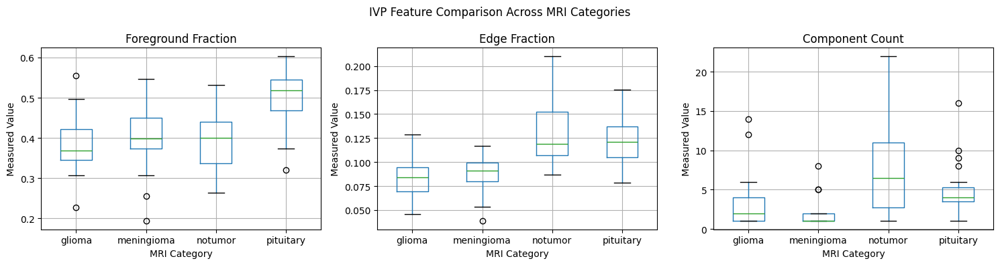

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("foreground_fraction", "Foreground Fraction"),
    ("edge_fraction", "Edge Fraction"),
    ("component_count", "Component Count")
]

for ax, (column, title) in zip(axes, metrics):
    analysis_df.boxplot(
        column=column,
        by="class_name",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("MRI Category")
    ax.set_ylabel("Measured Value")

plt.suptitle("IVP Feature Comparison Across MRI Categories")
plt.tight_layout()
plt.show()

In [89]:
from tqdm.auto import tqdm
import pandas as pd
import numpy as np

calibration_features = []

for record in tqdm(calibration_images, desc="Extracting IVP features"):
    try:
        result = process_mri(record["path"])

        calibration_features.append({
            "path": record["path"],
            "class_name": record["class_name"],
            "label": record["label"],
            "otsu_threshold": result["otsu_threshold"],
            "foreground_fraction": float(
                np.mean(result["cleaned_mask"] > 0)
            ),
            "edge_fraction": float(
                np.mean(result["edges"] > 0)
            ),
            "component_count": len(result["components"])
        })

    except (ValueError, cv2.error) as error:
        print(f"Skipped: {record['path']} — {error}")

calibration_df = pd.DataFrame(calibration_features)

print("Total images processed:", len(calibration_df))
print("\nClass distribution:")
display(calibration_df["class_name"].value_counts().to_frame("Images"))

print("\nFirst five feature records:")
display(calibration_df.head())

Extracting IVP features:   0%|          | 0/4480 [00:00<?, ?it/s]

Total images processed: 4480

Class distribution:


,Images
class_name,
notumor,1133
pituitary,1129
glioma,1125
meningioma,1093



First five feature records:


,path,class_name,label,otsu_threshold,foreground_fraction,edge_fraction,component_count
0,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1,67.0,0.313263,0.079285,1
1,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1,48.0,0.375473,0.053421,1
2,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma,1,78.0,0.424438,0.102798,2
3,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,1,68.0,0.362030,0.069778,1
4,/kaggle/input/brain-tumor-mri-dataset/Training...,notumor,0,80.0,0.459564,0.197784,11


In [90]:
# Compare average IVP features for both groups

comparison = calibration_df.groupby("label")[
    ["foreground_fraction", "edge_fraction", "component_count"]
].mean().round(4)

comparison.index = ["No Tumor", "Tumor-Labeled"]
display(comparison)

,foreground_fraction,edge_fraction,component_count
No Tumor,0.4276,0.1322,7.4060
Tumor-Labeled,0.4420,0.0975,3.9549


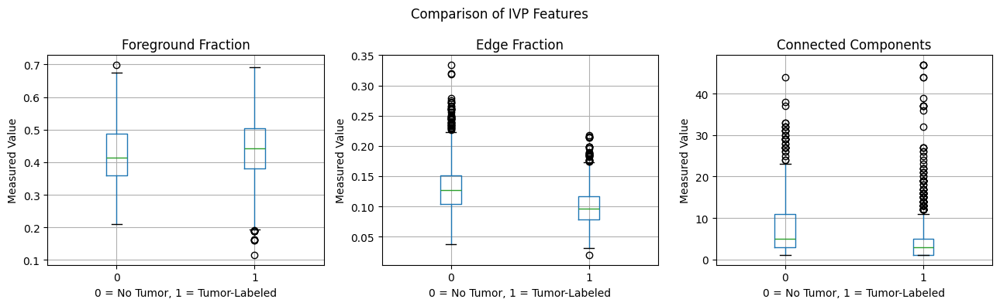

In [91]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

features = [
    ("foreground_fraction", "Foreground Fraction"),
    ("edge_fraction", "Edge Fraction"),
    ("component_count", "Connected Components")
]

for ax, (feature, title) in zip(axes, features):
    calibration_df.boxplot(
        column=feature,
        by="label",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("0 = No Tumor, 1 = Tumor-Labeled")
    ax.set_ylabel("Measured Value")

plt.suptitle("Comparison of IVP Features")
plt.tight_layout()
plt.show()

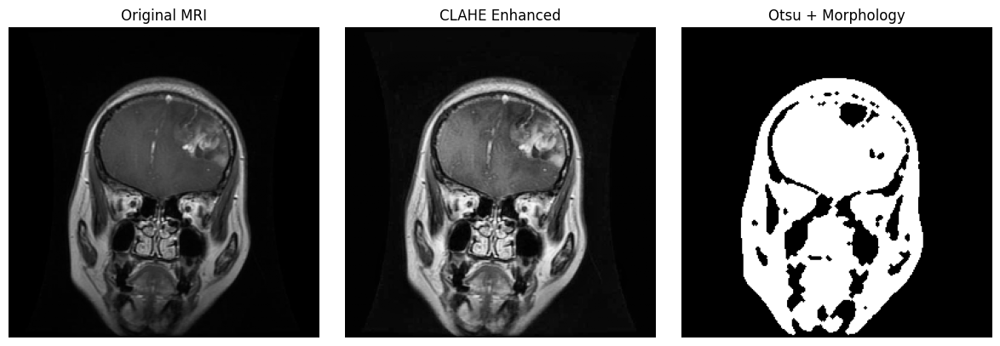

In [92]:
# Select one tumor-labeled MRI image
sample_record = next(
    r for r in calibration_images
    if r["label"] == 1
)

result = process_mri(sample_record["path"])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(result["original"], cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(result["enhanced"], cmap="gray")
axes[1].set_title("CLAHE Enhanced")

axes[2].imshow(result["cleaned_mask"], cmap="gray")
axes[2].set_title("Otsu + Morphology")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

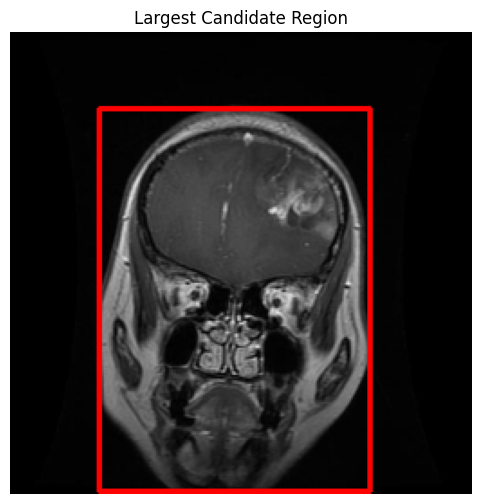

Candidate region area: 20530 pixels


In [93]:
# Find the largest connected region in the cleaned mask

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    result["cleaned_mask"],
    connectivity=8
)

if num_labels > 1:
    # Ignore the background (label 0)
    largest_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

    x = stats[largest_idx, cv2.CC_STAT_LEFT]
    y = stats[largest_idx, cv2.CC_STAT_TOP]
    w = stats[largest_idx, cv2.CC_STAT_WIDTH]
    h = stats[largest_idx, cv2.CC_STAT_HEIGHT]
    area = stats[largest_idx, cv2.CC_STAT_AREA]

    output = cv2.cvtColor(result["original"], cv2.COLOR_GRAY2RGB)

    cv2.rectangle(output, (x, y), (x + w, y + h), (255, 0, 0), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(output)
    plt.title("Largest Candidate Region")
    plt.axis("off")
    plt.show()

    print("Candidate region area:", area, "pixels")
else:
    print("No foreground region detected.")

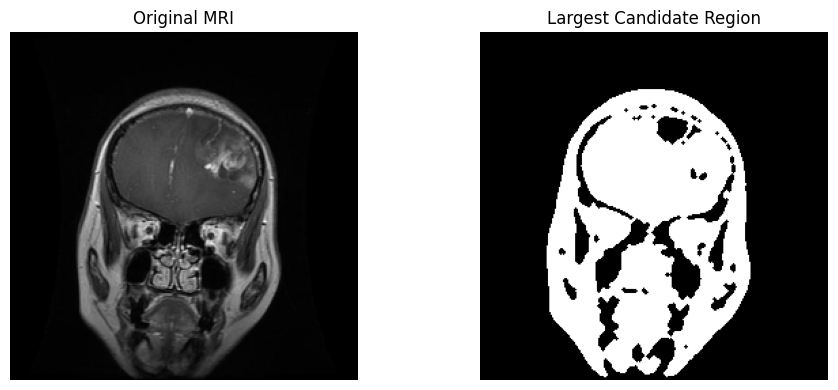

Candidate area (pixels): 20530
Candidate area (% of image): 31.33 %


In [94]:
# Create a binary mask for the largest candidate region

candidate_mask = np.zeros_like(result["cleaned_mask"])

if num_labels > 1:
    candidate_mask[labels == largest_idx] = 255

# Display the candidate region separately
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(result["original"], cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(candidate_mask, cmap="gray")
axes[1].set_title("Largest Candidate Region")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Candidate area (pixels):", int(np.sum(candidate_mask > 0)))
print(
    "Candidate area (% of image):",
    round(100 * np.mean(candidate_mask > 0), 2), "%"
)

In [95]:
# Measure the selected region
image_area = result["original"].shape[0] * result["original"].shape[1]
candidate_area = int(np.sum(candidate_mask > 0))

candidate_percentage = (candidate_area / image_area) * 100

print(f"Total image area: {image_area} pixels")
print(f"Candidate area: {candidate_area} pixels")
print(f"Candidate percentage: {candidate_percentage:.2f}%")

if candidate_percentage < 1:
    print("Observation: The candidate region is very small.")
elif candidate_percentage < 30:
    print("Observation: The candidate covers part of the image.")
else:
    print("Observation: The candidate covers a large part of the image.")


Total image area: 65536 pixels
Candidate area: 20530 pixels
Candidate percentage: 31.33%
Observation: The candidate covers a large part of the image.


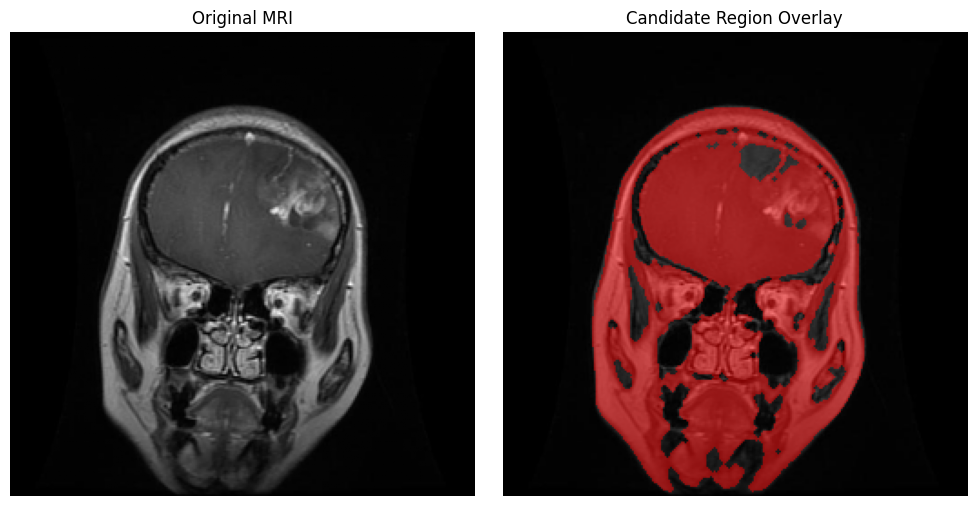

In [96]:
# Highlight the candidate region in red

overlay = cv2.cvtColor(result["original"], cv2.COLOR_GRAY2RGB)

mask = candidate_mask > 0
overlay[mask] = (
    0.5 * overlay[mask].astype(np.float32)
    + 0.5 * np.array([255, 0, 0], dtype=np.float32)
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(result["original"], cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(overlay)
axes[1].set_title("Candidate Region Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

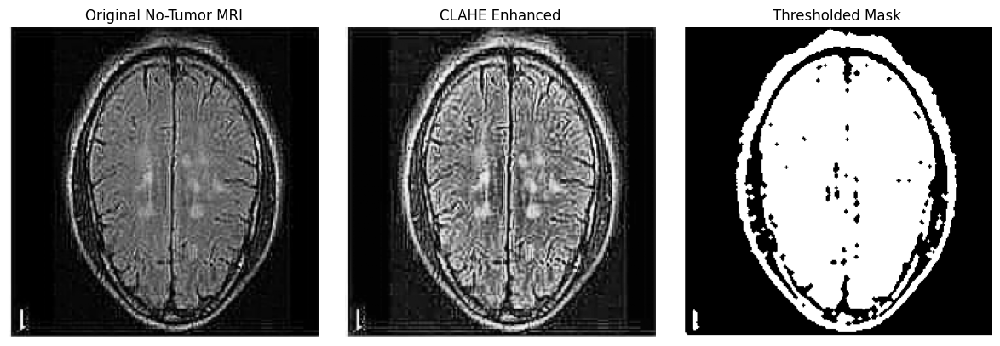

In [97]:
# Select one no-tumor image from the calibration set
normal_record = next(
    r for r in calibration_images
    if r["class_name"] == "notumor"
)

normal_result = process_mri(normal_record["path"])

# Display the processing results
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(normal_result["original"], cmap="gray")
axes[0].set_title("Original No-Tumor MRI")

axes[1].imshow(normal_result["enhanced"], cmap="gray")
axes[1].set_title("CLAHE Enhanced")

axes[2].imshow(normal_result["cleaned_mask"], cmap="gray")
axes[2].set_title("Thresholded Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [98]:
# Compare the two groups using existing IVP features

feature_comparison = calibration_df.groupby("label")[
    ["foreground_fraction", "edge_fraction"]
].mean().round(4)

feature_comparison.index = ["No Tumor", "Tumor-Labeled"]

display(feature_comparison)

foreground_diff = abs(
    feature_comparison.loc["No Tumor", "foreground_fraction"]
    - feature_comparison.loc["Tumor-Labeled", "foreground_fraction"]
)

edge_diff = abs(
    feature_comparison.loc["No Tumor", "edge_fraction"]
    - feature_comparison.loc["Tumor-Labeled", "edge_fraction"]
)

print("Difference in foreground fraction:", round(foreground_diff, 4))
print("Difference in edge fraction:", round(edge_diff, 4))

,foreground_fraction,edge_fraction
No Tumor,0.4276,0.1322
Tumor-Labeled,0.4420,0.0975


Difference in foreground fraction: 0.0144
Difference in edge fraction: 0.0347


In [99]:
# Try thresholds using calibration data only

normal_values = calibration_df.loc[
    calibration_df["label"] == 0, "foreground_fraction"
].values

tumor_values = calibration_df.loc[
    calibration_df["label"] == 1, "foreground_fraction"
].values

threshold_candidates = np.linspace(
    calibration_df["foreground_fraction"].min(),
    calibration_df["foreground_fraction"].max(),
    100
)

best_threshold = None
best_accuracy = -1

for threshold in threshold_candidates:
    predictions = (
        calibration_df["foreground_fraction"] < threshold
    ).astype(int)

    accuracy = np.mean(
        predictions == calibration_df["label"].values
    )

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

print("Selected threshold:", round(float(best_threshold), 4))
print("Calibration accuracy:", round(float(best_accuracy * 100), 2), "%")

Selected threshold: 0.6935
Calibration accuracy: 74.73 %


In [100]:
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

validation_features = []

for record in tqdm(validation_images, desc="Testing validation images"):
    result = process_mri(record["path"])

    validation_features.append({
        "path": record["path"],
        "class_name": record["class_name"],
        "label": record["label"],
        "foreground_fraction": float(
            np.mean(result["cleaned_mask"] > 0)
        )
    })

validation_df = pd.DataFrame(validation_features)

# Apply the threshold selected in Step 27
validation_df["prediction"] = (
    validation_df["foreground_fraction"] < best_threshold
).astype(int)

accuracy = np.mean(
    validation_df["prediction"] == validation_df["label"]
)

print(f"Validation accuracy: {accuracy * 100:.2f}%")
print("\nActual vs predicted:")
display(pd.crosstab(
    validation_df["label"],
    validation_df["prediction"],
    rownames=["Actual (0=No Tumor, 1=Tumor-Labeled)"],
    colnames=["Predicted"]
))

Testing validation images:   0%|          | 0/1120 [00:00<?, ?it/s]

Validation accuracy: 76.16%

Actual vs predicted:


Predicted,0,1
"Actual (0=No Tumor, 1=Tumor-Labeled)",,
0,1,266
1,1,852


In [101]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_true = validation_df["label"]
y_pred = validation_df["prediction"]

print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_true, y_pred, zero_division=0) * 100, 2), "%")

print("\nDetailed Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["No Tumor", "Tumor-Labeled"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

Accuracy: 76.16 %
Precision: 76.21 %
Recall: 99.88 %
F1 Score: 86.45 %

Detailed Report:
               precision    recall  f1-score   support

     No Tumor       0.50      0.00      0.01       267
Tumor-Labeled       0.76      1.00      0.86       853

     accuracy                           0.76      1120
    macro avg       0.63      0.50      0.44      1120
 weighted avg       0.70      0.76      0.66      1120

Confusion Matrix:
[[  1 266]
 [  1 852]]


Correct predictions: 853
Incorrect predictions: 267


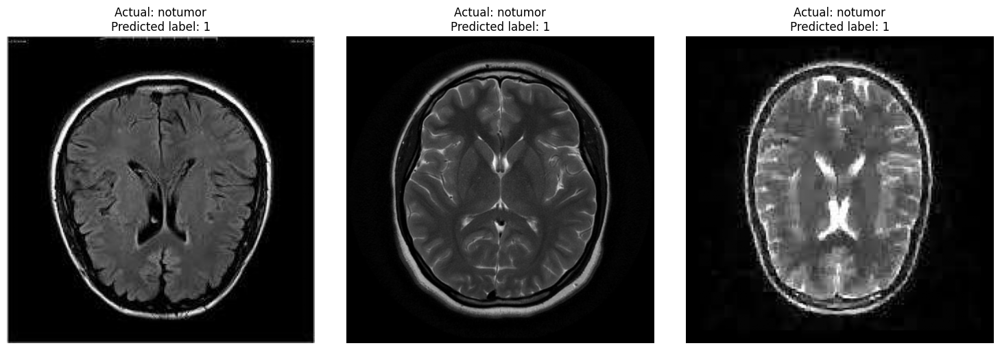

In [102]:
import matplotlib.pyplot as plt
import random

# Find correct and incorrect predictions
correct = validation_df[
    validation_df["label"] == validation_df["prediction"]
]

incorrect = validation_df[
    validation_df["label"] != validation_df["prediction"]
]

print("Correct predictions:", len(correct))
print("Incorrect predictions:", len(incorrect))

# Display up to 3 incorrect examples
if len(incorrect) > 0:
    samples = incorrect.sample(
        n=min(3, len(incorrect)),
        random_state=42
    )

    fig, axes = plt.subplots(
        1, len(samples),
        figsize=(5 * len(samples), 5)
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, samples.iterrows()):
        image = cv2.imread(row["path"], cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"Actual: {row['class_name']}\n"
            f"Predicted label: {row['prediction']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions in this validation set.")

In [103]:
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

test_features = []

for record in tqdm(testing_images, desc="Testing unseen images"):
    result = process_mri(record["path"])

    foreground_fraction = float(
        np.mean(result["cleaned_mask"] > 0)
    )

    prediction = int(
        foreground_fraction < best_threshold
    )

    test_features.append({
        "path": record["path"],
        "class_name": record["class_name"],
        "label": record["label"],
        "prediction": prediction,
        "foreground_fraction": foreground_fraction
    })

test_df = pd.DataFrame(test_features)

test_accuracy = np.mean(
    test_df["label"] == test_df["prediction"]
)

print(f"Testing accuracy: {test_accuracy * 100:.2f}%")
print("\nActual vs predicted:")
display(pd.crosstab(
    test_df["label"],
    test_df["prediction"],
    rownames=["Actual"],
    colnames=["Predicted"],
    dropna=False
))

Testing unseen images:   0%|          | 0/1600 [00:00<?, ?it/s]

Testing accuracy: 74.94%

Actual vs predicted:


Predicted,0,1
Actual,,
0,0,400
1,1,1199


In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_true = test_df["label"]
y_pred = test_df["prediction"]

print("FINAL TEST RESULTS")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0) * 100:.2f}%")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0) * 100:.2f}%")
print(f"F1 Score:  {f1_score(y_true, y_pred, zero_division=0) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["No Tumor", "Tumor-Labeled"],
    zero_division=0
))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=[0, 1]),
    index=["Actual No Tumor", "Actual Tumor-Labeled"],
    columns=["Predicted No Tumor", "Predicted Tumor-Labeled"]
))

FINAL TEST RESULTS
------------------------------
Accuracy:  74.94%
Precision: 74.98%
Recall:    99.92%
F1 Score:  85.67%

Classification Report:
               precision    recall  f1-score   support

     No Tumor       0.00      0.00      0.00       400
Tumor-Labeled       0.75      1.00      0.86      1200

     accuracy                           0.75      1600
    macro avg       0.37      0.50      0.43      1600
 weighted avg       0.56      0.75      0.64      1600

Confusion Matrix:


,Predicted No Tumor,Predicted Tumor-Labeled
Actual No Tumor,0,400
Actual Tumor-Labeled,1,1199


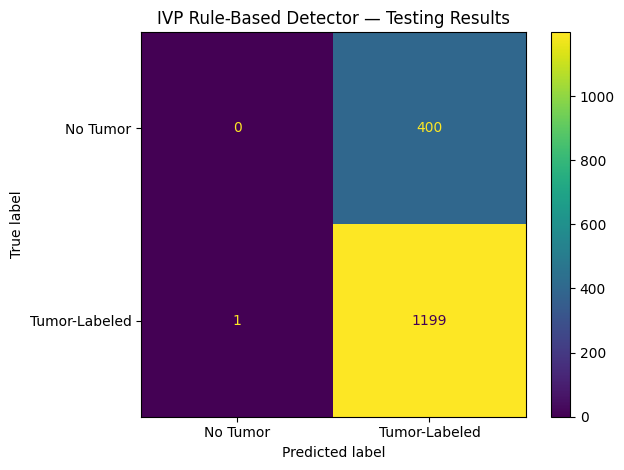

In [105]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_df["prediction"],
    labels=[0, 1],
    display_labels=["No Tumor", "Tumor-Labeled"],
    values_format="d"
)

plt.title("IVP Rule-Based Detector — Testing Results")
plt.tight_layout()
plt.show()


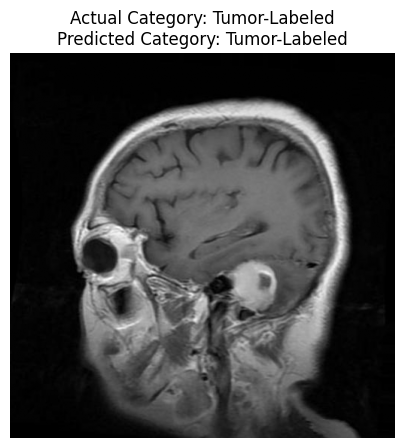

Actual category: Tumor-Labeled
Predicted category: Tumor-Labeled


In [106]:
# Select one image from the Testing dataset
sample = test_df.sample(n=1, random_state=42).iloc[0]

image = cv2.imread(sample["path"], cv2.IMREAD_GRAYSCALE)

actual_label = "Tumor-Labeled" if sample["label"] == 1 else "No Tumor"
predicted_label = (
    "Tumor-Labeled" if sample["prediction"] == 1 else "No Tumor"
)

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray")
plt.title(
    f"Actual Category: {actual_label}\n"
    f"Predicted Category: {predicted_label}"
)
plt.axis("off")
plt.show()

print("Actual category:", actual_label)
print("Predicted category:", predicted_label)

In [107]:
# Evaluate the binary detector for each original MRI category

category_results = (
    test_df.groupby("class_name")
    .apply(
        lambda group: pd.Series({
            "Total Images": len(group),
            "Correct Predictions": int(
                (group["label"] == group["prediction"]).sum()
            ),
            "Accuracy (%)": round(
                (group["label"] == group["prediction"]).mean() * 100,
                2
            )
        }),
        include_groups=False
    )
)

display(category_results)

,Total Images,Correct Predictions,Accuracy (%)
class_name,,,
glioma,400.0,400.0,100.00
meningioma,400.0,399.0,99.75
notumor,400.0,0.0,0.00
pituitary,400.0,400.0,100.00


In [108]:
# Save the testing results
test_df.to_csv("brain_tumor_ivp_test_results.csv", index=False)

# Save overall evaluation metrics
final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score (%)": [
        accuracy_score(test_df["label"], test_df["prediction"]) * 100,
        precision_score(test_df["label"], test_df["prediction"], zero_division=0) * 100,
        recall_score(test_df["label"], test_df["prediction"], zero_division=0) * 100,
        f1_score(test_df["label"], test_df["prediction"], zero_division=0) * 100
    ]
})

final_metrics["Score (%)"] = final_metrics["Score (%)"].round(2)
final_metrics.to_csv("brain_tumor_ivp_metrics.csv", index=False)

display(final_metrics)

print("Both CSV files saved successfully.")

,Metric,Score (%)
0,Accuracy,74.94
1,Precision,74.98
2,Recall,99.92
3,F1 Score,85.67


Both CSV files saved successfully.


In [109]:
from google.colab import files

files.download("brain_tumor_ivp_test_results.csv")
files.download("brain_tumor_ivp_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [110]:
# Extract the largest connected region's area for each image

def get_largest_region_area(image_path):
    processed = process_mri(image_path)
    mask = processed["cleaned_mask"]

    num_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(mask, connectivity=8)
    )

    if num_labels <= 1:
        return 0

    areas = stats[1:, cv2.CC_STAT_AREA]
    return int(np.max(areas))


# Compare a small sample from each category
region_records = []

for class_name in CLASSES:
    class_records = [
        r for r in calibration_images
        if r["class_name"] == class_name
    ]

    random.seed(42)
    selected = random.sample(
        class_records,
        min(10, len(class_records))
    )

    for record in selected:
        area = get_largest_region_area(record["path"])

        region_records.append({
            "class_name": class_name,
            "label": record["label"],
            "largest_region_area": area
        })

region_df = pd.DataFrame(region_records)

display(
    region_df.groupby("class_name")["largest_region_area"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

,mean,median,min,max
class_name,,,,
glioma,26315.4,25095.0,14880,36333
meningioma,26936.9,26461.0,23233,31951
notumor,24067.1,22889.0,14064,34869
pituitary,32561.5,33206.0,24497,39541


<Figure size 900x500 with 0 Axes>

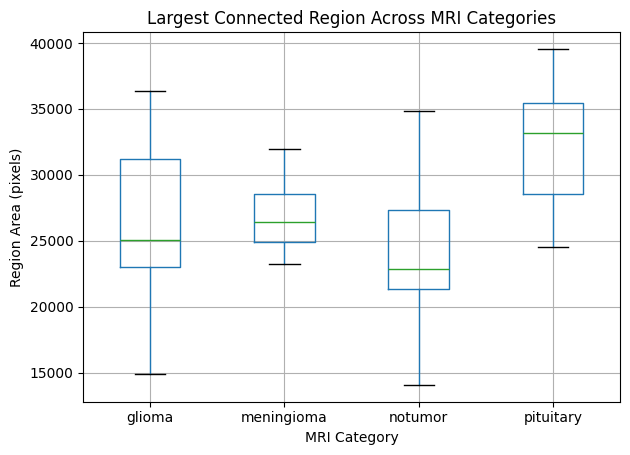

In [111]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

region_df.boxplot(
    column="largest_region_area",
    by="class_name"
)

plt.title("Largest Connected Region Across MRI Categories")
plt.suptitle("")
plt.xlabel("MRI Category")
plt.ylabel("Region Area (pixels)")
plt.tight_layout()
plt.show()

In [112]:
region_df["region_fraction"] = (
    region_df["largest_region_area"] / (256 * 256)
)

display(
    region_df.groupby("class_name")["region_fraction"]
    .agg(["mean", "median"])
    .round(4)
)

,mean,median
class_name,,
glioma,0.4015,0.3829
meningioma,0.4110,0.4038
notumor,0.3672,0.3493
pituitary,0.4968,0.5067


In [113]:
# Count incorrect predictions for each MRI category

test_df["correct"] = (
    test_df["label"] == test_df["prediction"]
)

error_summary = test_df.groupby("class_name").agg(
    Total_Images=("correct", "size"),
    Correct=("correct", "sum")
)

error_summary["Incorrect"] = (
    error_summary["Total_Images"] - error_summary["Correct"]
)

error_summary["Accuracy_Percent"] = (
    error_summary["Correct"] / error_summary["Total_Images"] * 100
).round(2)

display(error_summary)

,Total_Images,Correct,Incorrect,Accuracy_Percent
class_name,,,,
glioma,400,400,0,100.00
meningioma,400,399,1,99.75
notumor,400,0,400,0.00
pituitary,400,400,0,100.00


Incorrect predictions: 401


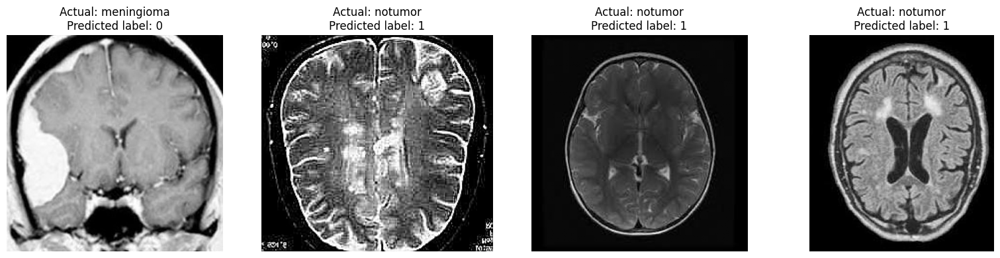

In [114]:
# Display up to 4 incorrectly classified test images

wrong_predictions = test_df[
    test_df["label"] != test_df["prediction"]
]

print("Incorrect predictions:", len(wrong_predictions))

if len(wrong_predictions) > 0:
    samples = wrong_predictions.head(4)

    fig, axes = plt.subplots(
        1, len(samples),
        figsize=(4 * len(samples), 4)
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, samples.iterrows()):
        image = cv2.imread(
            row["path"],
            cv2.IMREAD_GRAYSCALE
        )

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"Actual: {row['class_name']}\n"
            f"Predicted label: {row['prediction']}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions in this test set.")

In [115]:
# Summarize actual image-processing features by category

test_feature_summary = test_df.groupby("class_name").agg(
    Images=("label", "size"),
    Mean_Foreground=("foreground_fraction", "mean")
).round(4)

display(test_feature_summary)

,Images,Mean_Foreground
class_name,,
glioma,400,0.4222
meningioma,400,0.4287
notumor,400,0.4172
pituitary,400,0.5160


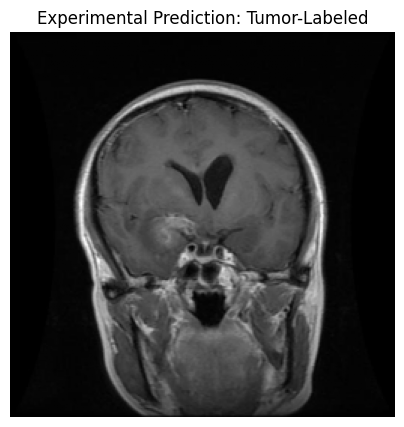

In [116]:
def predict_mri(image_path):
    result = process_mri(image_path)

    foreground_fraction = float(
        np.mean(result["cleaned_mask"] > 0)
    )

    prediction = (
        "Tumor-Labeled"
        if foreground_fraction < best_threshold
        else "No Tumor"
    )

    return result, prediction


# Test the function on one existing MRI
sample_path = test_df.iloc[0]["path"]

result, prediction = predict_mri(sample_path)

plt.figure(figsize=(5, 5))
plt.imshow(result["original"], cmap="gray")
plt.title(f"Experimental Prediction: {prediction}")
plt.axis("off")
plt.show()

Saving brain.jpg to brain.jpg


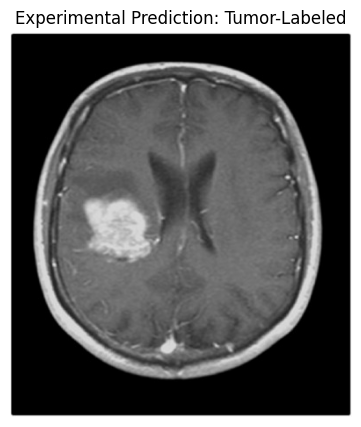

Prediction: Tumor-Labeled
Note: This is an experimental IVP rule, not a medical diagnosis.


In [117]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if uploaded:
    image_name = next(iter(uploaded))
    image_bytes = np.frombuffer(
        uploaded[image_name], dtype=np.uint8
    )
    image = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("Please upload a valid MRI image.")
    else:
        result, prediction = predict_mri(image_name)

        plt.figure(figsize=(6, 5))
        plt.imshow(image, cmap="gray")
        plt.title(f"Experimental Prediction: {prediction}")
        plt.axis("off")
        plt.show()

        print("Prediction:", prediction)
        print("Note: This is an experimental IVP rule, not a medical diagnosis.")

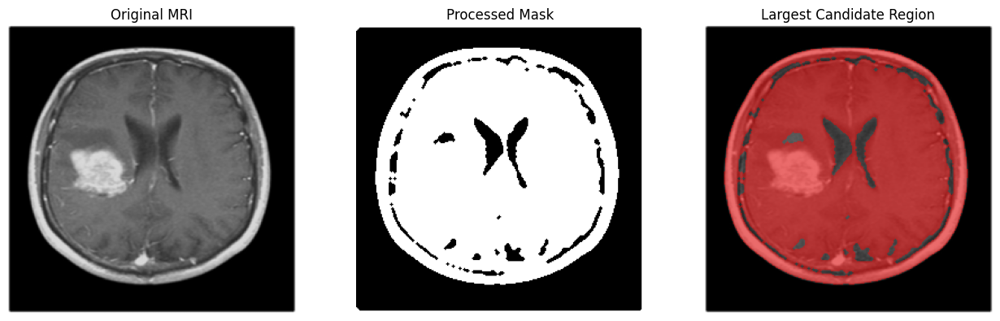

In [118]:
# Process the uploaded MRI image
result = process_mri(image_name)

# Find connected regions in the cleaned mask
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        result["cleaned_mask"],
        connectivity=8
    )
)

# Select the largest foreground region, if present
if num_labels > 1:
    largest_idx = 1 + np.argmax(
        stats[1:, cv2.CC_STAT_AREA]
    )

    candidate_mask = np.zeros_like(
        result["cleaned_mask"]
    )
    candidate_mask[labels == largest_idx] = 255

    # Highlight the candidate region in red
    overlay = cv2.cvtColor(
        result["original"],
        cv2.COLOR_GRAY2RGB
    )

    mask = candidate_mask > 0
    overlay[mask] = (
        0.5 * overlay[mask].astype(np.float32)
        + 0.5 * np.array([255, 0, 0], dtype=np.float32)
    ).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    axes[0].imshow(result["original"], cmap="gray")
    axes[0].set_title("Original MRI")

    axes[1].imshow(result["cleaned_mask"], cmap="gray")
    axes[1].set_title("Processed Mask")

    axes[2].imshow(overlay)
    axes[2].set_title("Largest Candidate Region")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No candidate region found by thresholding.")

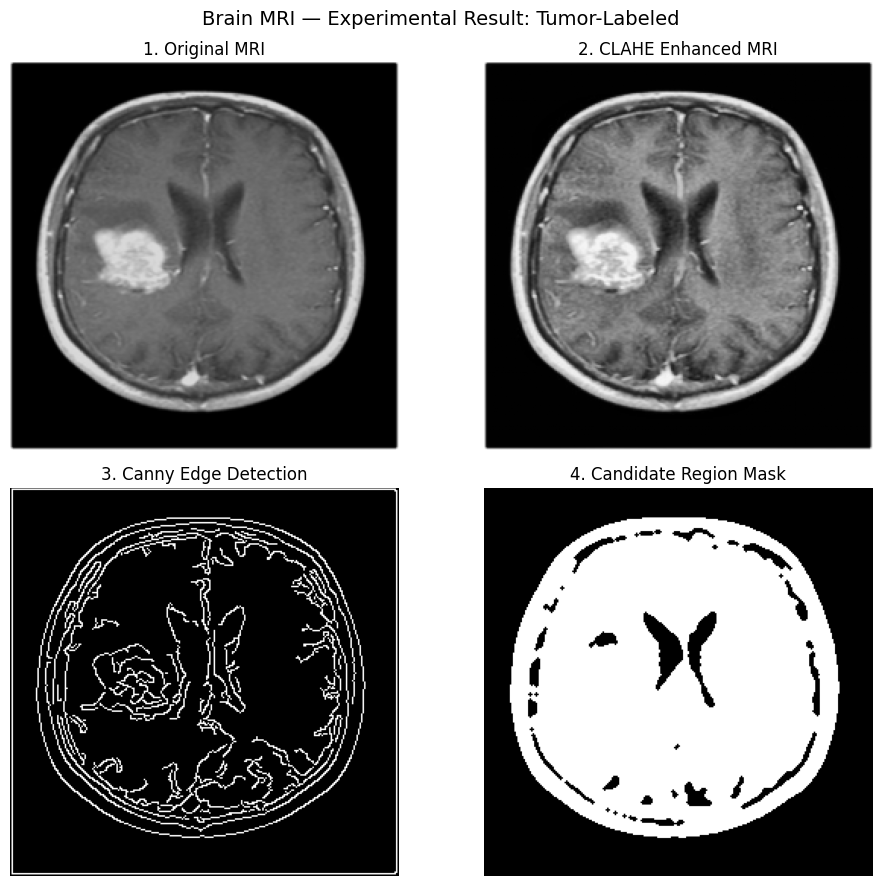

Experimental prediction: Tumor-Labeled
This is not a confirmed tumor diagnosis.


In [119]:
# Display the final IVP processing results

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

axes[0, 0].imshow(result["original"], cmap="gray")
axes[0, 0].set_title("1. Original MRI")

axes[0, 1].imshow(result["enhanced"], cmap="gray")
axes[0, 1].set_title("2. CLAHE Enhanced MRI")

axes[1, 0].imshow(result["edges"], cmap="gray")
axes[1, 0].set_title("3. Canny Edge Detection")

axes[1, 1].imshow(candidate_mask, cmap="gray")
axes[1, 1].set_title("4. Candidate Region Mask")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"Brain MRI — Experimental Result: {prediction}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Experimental prediction:", prediction)
print("This is not a confirmed tumor diagnosis.")

In [120]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

y_true = test_df["label"]
y_pred = test_df["prediction"]

metrics = {
    "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
    "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
    "Recall (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
    "F1 Score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
}

for name, value in metrics.items():
    print(f"{name}: {value:.2f}")

Accuracy (%): 74.94
Precision (%): 74.98
Recall (%): 99.92
F1 Score (%): 85.67


Saving brain1.jpg to brain1.jpg


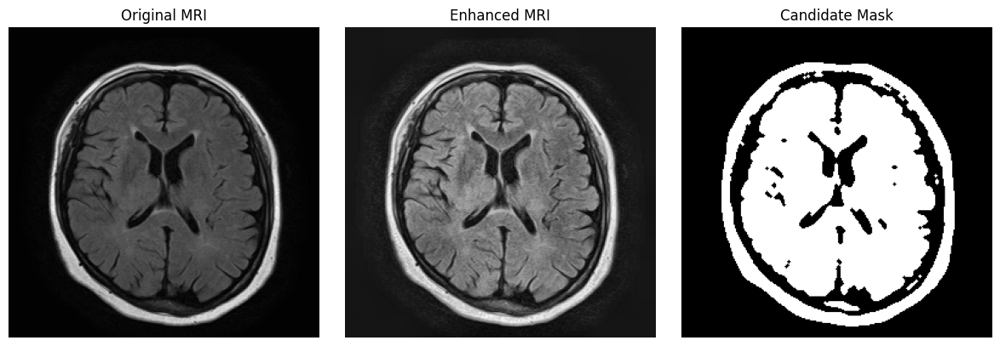

Experimental prediction: Tumor-Labeled
This is not a confirmed tumor diagnosis.


In [121]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

def upload_and_process_mri():
    uploaded = files.upload()

    if not uploaded:
        print("Please select an MRI image.")
        return

    filename = next(iter(uploaded))

    # Decode the uploaded image directly
    image_bytes = np.frombuffer(
        uploaded[filename], dtype=np.uint8
    )
    image = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("Invalid image. Please upload a JPG or PNG.")
        return

    # Save it so the existing pipeline can read it
    with open(filename, "wb") as f:
        f.write(uploaded[filename])

    processed = process_mri(filename)

    # Use the existing experimental rule
    foreground_fraction = float(
        np.mean(processed["cleaned_mask"] > 0)
    )
    prediction = (
        "Tumor-Labeled"
        if foreground_fraction < best_threshold
        else "No Tumor"
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(processed["original"], cmap="gray")
    axes[0].set_title("Original MRI")

    axes[1].imshow(processed["enhanced"], cmap="gray")
    axes[1].set_title("Enhanced MRI")

    axes[2].imshow(processed["cleaned_mask"], cmap="gray")
    axes[2].set_title("Candidate Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Experimental prediction:", prediction)
    print("This is not a confirmed tumor diagnosis.")

# Run the uploader
upload_and_process_mri()

In [122]:
# Check false positives and false negatives

normal_images = test_df[test_df["label"] == 0]
tumor_images = test_df[test_df["label"] == 1]

false_positives = normal_images[
    normal_images["prediction"] == 1
]

false_negatives = tumor_images[
    tumor_images["prediction"] == 0
]

print("Normal images incorrectly predicted as tumor:",
      len(false_positives), "/", len(normal_images))

print("Tumor-labeled images incorrectly predicted as normal:",
      len(false_negatives), "/", len(tumor_images))

print("\nPrediction counts:")
display(pd.crosstab(
    test_df["class_name"],
    test_df["prediction"],
    rownames=["Actual Category"],
    colnames=["Predicted Label (0=Normal, 1=Tumor-Labeled)"]
))

Normal images incorrectly predicted as tumor: 400 / 400
Tumor-labeled images incorrectly predicted as normal: 1 / 1200

Prediction counts:


"Predicted Label (0=Normal, 1=Tumor-Labeled)",0,1
Actual Category,,
glioma,0,400
meningioma,1,399
notumor,0,400
pituitary,0,400


In [123]:
# Calculate correct and incorrect predictions

test_df["correct"] = (
    test_df["label"] == test_df["prediction"]
)

results = test_df.groupby("class_name").agg(
    Total=("correct", "count"),
    Correct=("correct", "sum")
)

results["Incorrect"] = results["Total"] - results["Correct"]
results["Accuracy (%)"] = (
    results["Correct"] / results["Total"] * 100
).round(2)

display(results)

,Total,Correct,Incorrect,Accuracy (%)
class_name,,,,
glioma,400,400,0,100.00
meningioma,400,399,1,99.75
notumor,400,0,400,0.00
pituitary,400,400,0,100.00


In [124]:
# Evaluate false alarms on the test dataset

normal_images = test_df[test_df["label"] == 0]

false_positives = normal_images[
    normal_images["prediction"] == 1
]

if len(normal_images) > 0:
    false_positive_rate = (
        len(false_positives) / len(normal_images)
    ) * 100

    print("Total no-tumor images:", len(normal_images))
    print("Incorrectly predicted as tumor:", len(false_positives))
    print(f"False-positive rate: {false_positive_rate:.2f}%")
else:
    print("No no-tumor images found in test_df.")

Total no-tumor images: 400
Incorrectly predicted as tumor: 400
False-positive rate: 100.00%


In [125]:
# Evaluate missed tumor-labeled images

tumor_images = test_df[test_df["label"] == 1]

false_negatives = tumor_images[
    tumor_images["prediction"] == 0
]

if len(tumor_images) > 0:
    false_negative_rate = (
        len(false_negatives) / len(tumor_images)
    ) * 100

    print("Total tumor-labeled images:", len(tumor_images))
    print("Missed by detector:", len(false_negatives))
    print(f"False-negative rate: {false_negative_rate:.2f}%")
else:
    print("No tumor-labeled images found in test_df.")

Total tumor-labeled images: 1200
Missed by detector: 1
False-negative rate: 0.08%


In [126]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

y_true = test_df["label"]
y_pred = test_df["prediction"]

# Summary of test performance
final_summary = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1 Score (%)"
    ],
    "Value": [
        accuracy_score(y_true, y_pred) * 100,
        precision_score(y_true, y_pred, zero_division=0) * 100,
        recall_score(y_true, y_pred, zero_division=0) * 100,
        f1_score(y_true, y_pred, zero_division=0) * 100
    ]
})

final_summary["Value"] = final_summary["Value"].round(2)
display(final_summary)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display(pd.DataFrame(
    cm,
    index=["Actual No Tumor", "Actual Tumor-Labeled"],
    columns=["Predicted No Tumor", "Predicted Tumor-Labeled"]
))

# Save summary
final_summary.to_csv("final_ivp_evaluation.csv", index=False)
print("Saved: final_ivp_evaluation.csv")

,Metric,Value
0,Accuracy (%),74.94
1,Precision (%),74.98
2,Recall (%),99.92
3,F1 Score (%),85.67


,Predicted No Tumor,Predicted Tumor-Labeled
Actual No Tumor,0,400
Actual Tumor-Labeled,1,1199


Saved: final_ivp_evaluation.csv


In [127]:
from google.colab import files

files.download("final_ivp_evaluation.csv")
files.download("brain_tumor_ivp_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [128]:
print("=" * 50)
print("BRAIN TUMOR DETECTION USING IMAGE PROCESSING")
print("=" * 50)

print("\nTechniques Used:")
print("1. Grayscale conversion and image resizing")
print("2. CLAHE contrast enhancement")
print("3. Gaussian filtering")
print("4. Canny edge detection")
print("5. Otsu thresholding")
print("6. Morphological operations")
print("7. Connected component analysis")

print("\nClassification Approach:")
print("Simple handcrafted threshold rule")

print("\nEvaluation:")
print(final_summary.to_string(index=False))

print("\nLimitation:")
print("Candidate regions are not confirmed tumor regions.")
print("The experimental rule is not a medical diagnosis.")

BRAIN TUMOR DETECTION USING IMAGE PROCESSING

Techniques Used:
1. Grayscale conversion and image resizing
2. CLAHE contrast enhancement
3. Gaussian filtering
4. Canny edge detection
5. Otsu thresholding
6. Morphological operations
7. Connected component analysis

Classification Approach:
Simple handcrafted threshold rule

Evaluation:
       Metric  Value
 Accuracy (%)  74.94
Precision (%)  74.98
   Recall (%)  99.92
 F1 Score (%)  85.67

Limitation:
Candidate regions are not confirmed tumor regions.
The experimental rule is not a medical diagnosis.


In [129]:
print("""
PROJECT CONCLUSION
------------------

This project applies classical Image and Video Processing
techniques to brain MRI images.

The pipeline includes contrast enhancement using CLAHE,
Gaussian filtering, Canny edge detection, Otsu thresholding,
morphological operations, and connected component analysis.

A simple handcrafted threshold rule was tested to distinguish
tumor-labeled images from no-tumor images.

The testing metrics show the performance of this experimental
rule on the selected dataset. However, threshold-based image
processing may also identify normal brain tissue as a candidate
region, so the highlighted region cannot be confirmed as a tumor.

The current prototype demonstrates classical IVP techniques,
but further validation and improvement are required before it
can be considered a reliable tumor detection system.
""")


PROJECT CONCLUSION
------------------

This project applies classical Image and Video Processing
techniques to brain MRI images.

The pipeline includes contrast enhancement using CLAHE,
Gaussian filtering, Canny edge detection, Otsu thresholding,
morphological operations, and connected component analysis.

A simple handcrafted threshold rule was tested to distinguish
tumor-labeled images from no-tumor images.

The testing metrics show the performance of this experimental
rule on the selected dataset. However, threshold-based image
processing may also identify normal brain tissue as a candidate
region, so the highlighted region cannot be confirmed as a tumor.

The current prototype demonstrates classical IVP techniques,
but further validation and improvement are required before it
can be considered a reliable tumor detection system.



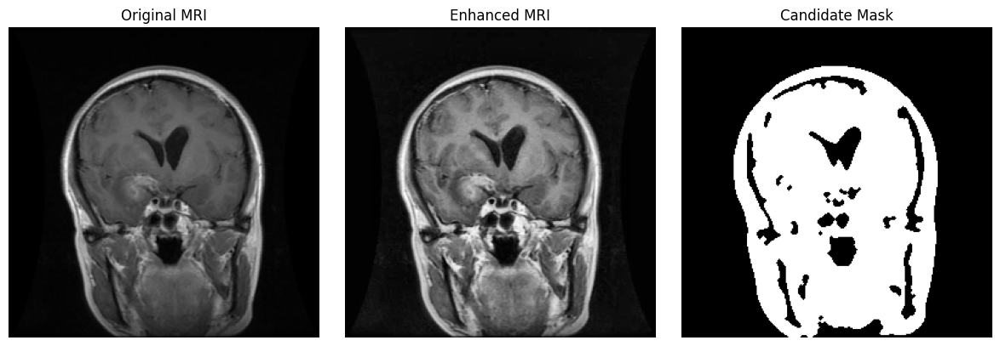

Experimental prediction: Tumor-Labeled
Foreground fraction: 0.4136
Note: This is not a confirmed tumor diagnosis.


In [130]:
def show_mri_result(image_path):
    processed = process_mri(image_path)

    foreground_fraction = float(
        np.mean(processed["cleaned_mask"] > 0)
    )

    prediction = (
        "Tumor-Labeled"
        if foreground_fraction < best_threshold
        else "No Tumor"
    )

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(processed["original"], cmap="gray")
    axes[0].set_title("Original MRI")

    axes[1].imshow(processed["enhanced"], cmap="gray")
    axes[1].set_title("Enhanced MRI")

    axes[2].imshow(processed["cleaned_mask"], cmap="gray")
    axes[2].set_title("Candidate Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Experimental prediction:", prediction)
    print("Foreground fraction:", round(foreground_fraction, 4))
    print("Note: This is not a confirmed tumor diagnosis.")

# Try it on a test image
show_mri_result(test_df.iloc[0]["path"])

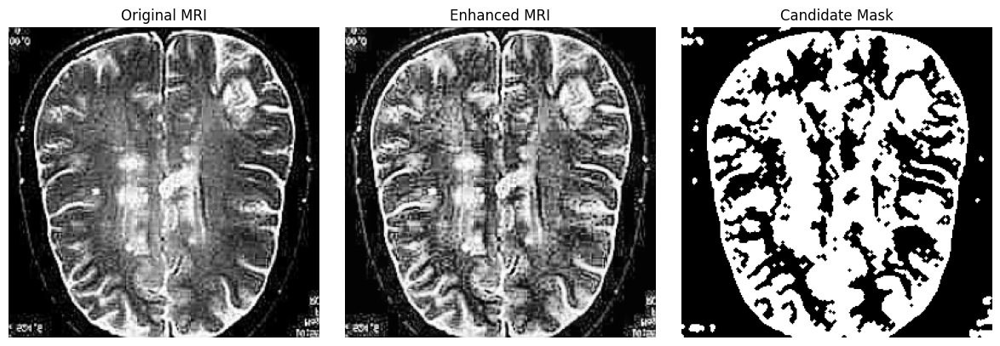

Experimental prediction: Tumor-Labeled
Foreground fraction: 0.4621
Note: This is not a confirmed tumor diagnosis.


In [131]:
# Select a known no-tumor image from the Testing dataset
normal_sample = next(
    record for record in testing_images
    if record["class_name"] == "notumor"
)

show_mri_result(normal_sample["path"])

In [132]:
# Show the detector's results for each MRI category

category_summary = test_df.groupby("class_name").agg(
    Total_Images=("label", "size"),
    Correct_Predictions=(
        "prediction",
        lambda p: int(
            (p == test_df.loc[p.index, "label"]).sum()
        )
    )
)

category_summary["Accuracy (%)"] = (
    category_summary["Correct_Predictions"]
    / category_summary["Total_Images"] * 100
).round(2)

display(category_summary)

,Total_Images,Correct_Predictions,Accuracy (%)
class_name,,,
glioma,400,400,100.00
meningioma,400,399,99.75
notumor,400,0,0.00
pituitary,400,400,100.00


In [133]:
# Save category-wise testing results

category_summary.to_csv(
    "brain_tumor_category_evaluation.csv"
)

print("Category-wise evaluation saved successfully.")

display(category_summary)

Category-wise evaluation saved successfully.


,Total_Images,Correct_Predictions,Accuracy (%)
class_name,,,
glioma,400,400,100.00
meningioma,400,399,99.75
notumor,400,0,0.00
pituitary,400,400,100.00


In [134]:
from google.colab import files

files.download("brain_tumor_category_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving brain1.jpg to brain1 (1).jpg


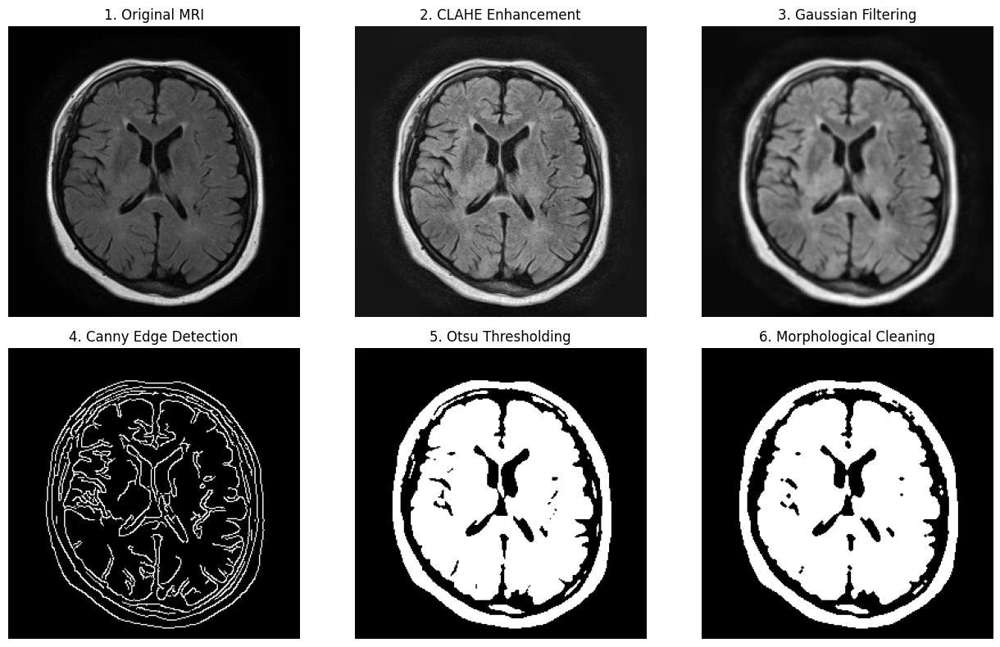

Image processing completed successfully.
Otsu threshold: 81.0
Foreground percentage: 40.69 %
Note: The mask is not a confirmed tumor segmentation.


In [135]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Upload MRI image
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))

    # Read uploaded image
    image_bytes = np.frombuffer(
        uploaded[filename], dtype=np.uint8
    )
    image = cv2.imdecode(
        image_bytes, cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        print("Invalid image. Upload a JPG or PNG.")
    else:
        # Apply IVP processing
        resized = cv2.resize(
            image, (256, 256),
            interpolation=cv2.INTER_AREA
        )

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        enhanced = clahe.apply(resized)

        smoothed = cv2.GaussianBlur(
            enhanced, (5, 5), 1.0
        )

        edges = cv2.Canny(smoothed, 50, 150)

        threshold, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel
        )
        cleaned = cv2.morphologyEx(
            cleaned, cv2.MORPH_CLOSE, kernel
        )

        # Display processing stages
        fig, axes = plt.subplots(2, 3, figsize=(13, 8))

        images = [
            (resized, "1. Original MRI"),
            (enhanced, "2. CLAHE Enhancement"),
            (smoothed, "3. Gaussian Filtering"),
            (edges, "4. Canny Edge Detection"),
            (mask, "5. Otsu Thresholding"),
            (cleaned, "6. Morphological Cleaning")
        ]

        for ax, (display_image, title) in zip(
            axes.flat, images
        ):
            ax.imshow(display_image, cmap="gray")
            ax.set_title(title)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        print("Image processing completed successfully.")
        print("Otsu threshold:", threshold)
        print(
            "Foreground percentage:",
            round(np.mean(cleaned > 0) * 100, 2), "%"
        )
        print(
            "Note: The mask is not a confirmed tumor segmentation."
        )

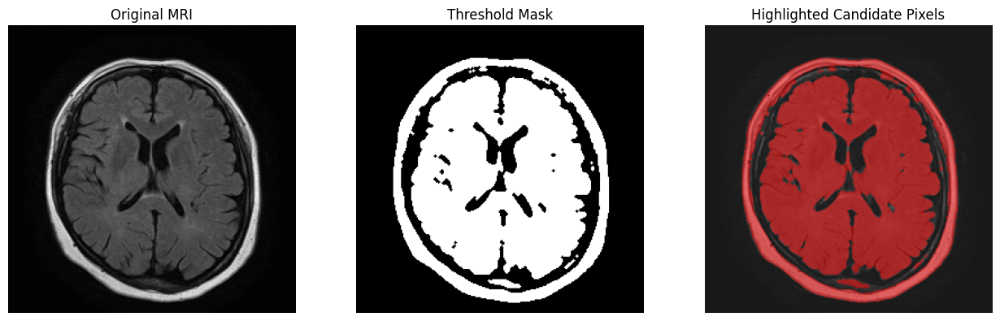

Red pixels indicate threshold-selected regions,
not confirmed tumor tissue.


In [136]:
# Step 64: Display candidate mask over the original MRI

# Use the cleaned mask from Step 63
overlay = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

candidate = cleaned > 0

# Highlight threshold-selected pixels in red
overlay[candidate] = (
    0.5 * overlay[candidate].astype(np.float32)
    + 0.5 * np.array([255, 0, 0], dtype=np.float32)
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(resized, cmap="gray")
axes[0].set_title("Original MRI")

axes[1].imshow(cleaned, cmap="gray")
axes[1].set_title("Threshold Mask")

axes[2].imshow(overlay)
axes[2].set_title("Highlighted Candidate Pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Red pixels indicate threshold-selected regions,")
print("not confirmed tumor tissue.")

In [137]:
# Label separate regions in the cleaned binary mask
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        cleaned,
        connectivity=8
    )
)

regions = []

# Skip label 0 because it represents the background
for i in range(1, num_labels):
    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    area = stats[i, cv2.CC_STAT_AREA]

    regions.append({
        "Region": i,
        "Area (pixels)": int(area),
        "Width": int(w),
        "Height": int(h)
    })

regions_df = pd.DataFrame(regions)

print("Number of foreground regions:", len(regions_df))
display(
    regions_df.sort_values(
        "Area (pixels)", ascending=False
    ).head(10)
)

Number of foreground regions: 8


,Region,Area (pixels),Width,Height
2,3,20405,160,181
0,1,6063,192,218
7,8,140,30,8
6,7,29,10,9
4,5,11,3,5
1,2,10,6,4
3,4,5,3,3
5,6,5,3,3


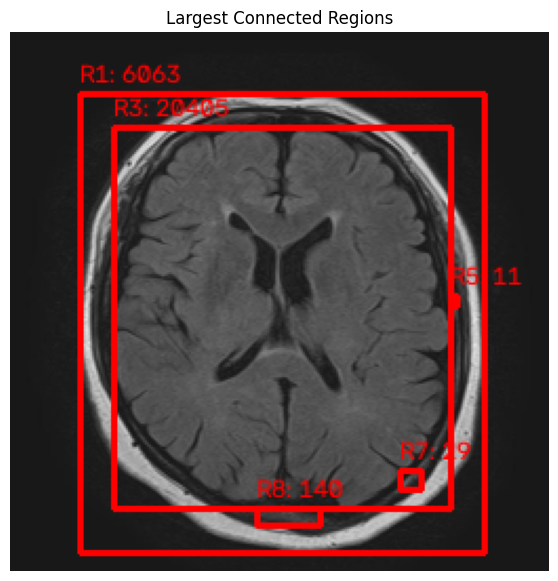

In [138]:
# Draw bounding boxes around the largest connected regions

output = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

# Ignore the background and sort regions by area
if num_labels > 1:
    largest_regions = sorted(
        range(1, num_labels),
        key=lambda i: stats[i, cv2.CC_STAT_AREA],
        reverse=True
    )[:5]

    for i in largest_regions:
        x = stats[i, cv2.CC_STAT_LEFT]
        y = stats[i, cv2.CC_STAT_TOP]
        w = stats[i, cv2.CC_STAT_WIDTH]
        h = stats[i, cv2.CC_STAT_HEIGHT]
        area = stats[i, cv2.CC_STAT_AREA]

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (255, 0, 0),
            2
        )

        cv2.putText(
            output,
            f"R{i}: {area}",
            (x, max(y - 5, 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (255, 0, 0),
            1
        )

plt.figure(figsize=(7, 7))
plt.imshow(output)
plt.title("Largest Connected Regions")
plt.axis("off")
plt.show()

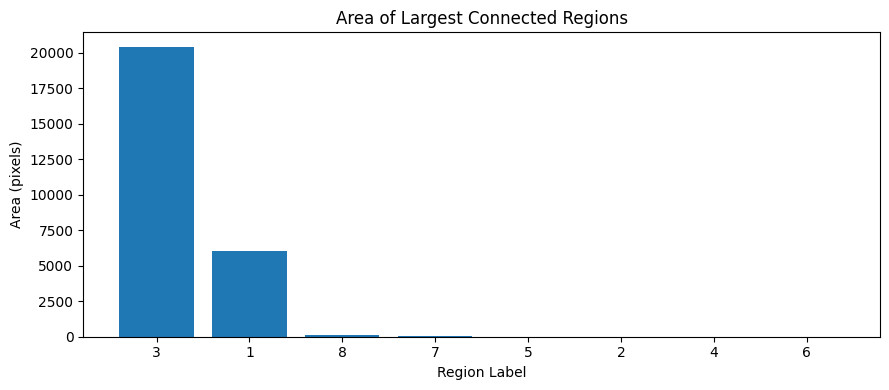

In [139]:
# Plot the areas of the detected connected regions

if not regions_df.empty:
    top_regions = (
        regions_df
        .sort_values("Area (pixels)", ascending=False)
        .head(10)
    )

    plt.figure(figsize=(9, 4))

    plt.bar(
        top_regions["Region"].astype(str),
        top_regions["Area (pixels)"]
    )

    plt.title("Area of Largest Connected Regions")
    plt.xlabel("Region Label")
    plt.ylabel("Area (pixels)")
    plt.tight_layout()
    plt.show()
else:
    print("No foreground regions detected.")

In [140]:
from IPython.display import display, Markdown

display(Markdown("""
# Brain MRI Image Processing — Implementation Summary

| Step | Technique | Purpose |
|---|---|---|
| 1 | Grayscale conversion | Simplify image representation |
| 2 | Image resizing | Standardize image dimensions |
| 3 | CLAHE | Improve local contrast |
| 4 | Gaussian filtering | Smooth image and reduce noise |
| 5 | Canny edge detection | Identify image boundaries |
| 6 | Otsu thresholding | Separate pixels by intensity |
| 7 | Morphological operations | Clean the binary mask |
| 8 | Connected components | Measure separate regions |

**Limitation:** The highlighted regions are generated through
classical image processing. They are not confirmed tumor regions.
The experimental binary prediction requires further validation.
"""))


# Brain MRI Image Processing — Implementation Summary

| Step | Technique | Purpose |
|---|---|---|
| 1 | Grayscale conversion | Simplify image representation |
| 2 | Image resizing | Standardize image dimensions |
| 3 | CLAHE | Improve local contrast |
| 4 | Gaussian filtering | Smooth image and reduce noise |
| 5 | Canny edge detection | Identify image boundaries |
| 6 | Otsu thresholding | Separate pixels by intensity |
| 7 | Morphological operations | Clean the binary mask |
| 8 | Connected components | Measure separate regions |

**Limitation:** The highlighted regions are generated through
classical image processing. They are not confirmed tumor regions.
The experimental binary prediction requires further validation.


Saving brain.jpg to brain (1).jpg


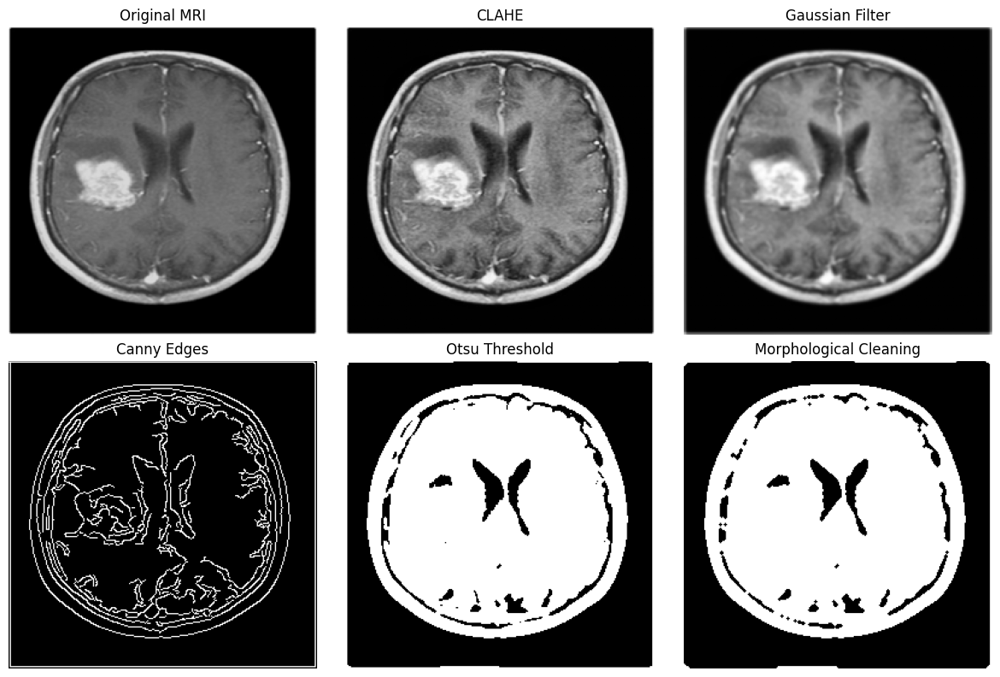

Live image-processing pipeline completed.
Otsu threshold: 72.00
Foreground fraction: 53.46%


In [141]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    data = np.frombuffer(uploaded[filename], dtype=np.uint8)
    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("Invalid image. Please upload a JPG or PNG.")
    else:
        resized = cv2.resize(image, (256, 256))
        enhanced = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(resized)
        smoothed = cv2.GaussianBlur(enhanced, (5, 5), 1.0)
        edges = cv2.Canny(smoothed, 50, 150)
        threshold, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel
        )
        cleaned = cv2.morphologyEx(
            cleaned, cv2.MORPH_CLOSE, kernel
        )

        fig, axes = plt.subplots(2, 3, figsize=(12, 8))
        stages = [
            (resized, "Original MRI"),
            (enhanced, "CLAHE"),
            (smoothed, "Gaussian Filter"),
            (edges, "Canny Edges"),
            (mask, "Otsu Threshold"),
            (cleaned, "Morphological Cleaning")
        ]

        for ax, (stage, title) in zip(axes.flat, stages):
            ax.imshow(stage, cmap="gray")
            ax.set_title(title)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        print("Live image-processing pipeline completed.")
        print(f"Otsu threshold: {threshold:.2f}")
        print(f"Foreground fraction: {np.mean(cleaned > 0) * 100:.2f}%")

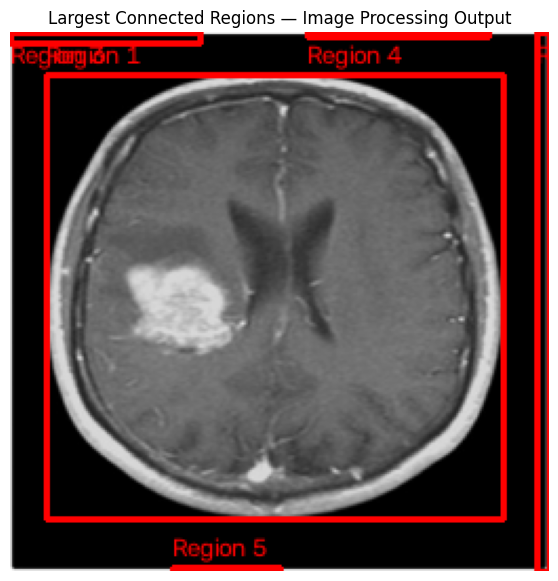

Candidate regions displayed: 5
Note: These regions are not confirmed tumor boundaries.


In [142]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find connected regions in the cleaned mask
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    cleaned, connectivity=8
)

# Draw bounding boxes around the largest regions
overlay = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

regions = []
for i in range(1, num_labels):
    x, y, w, h, area = stats[i]

    # Ignore very small regions
    if area >= 100:
        regions.append((area, x, y, w, h))

regions = sorted(regions, reverse=True)[:5]

for index, (area, x, y, w, h) in enumerate(regions, start=1):
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(
        overlay, f"Region {index}",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1
    )

plt.figure(figsize=(7, 7))
plt.imshow(overlay)
plt.title("Largest Connected Regions — Image Processing Output")
plt.axis("off")
plt.show()

print(f"Candidate regions displayed: {len(regions)}")
print("Note: These regions are not confirmed tumor boundaries.")

Saving brain1.jpg to brain1 (2).jpg
Foreground fraction: 40.86%
Experimental Prediction: Tumor


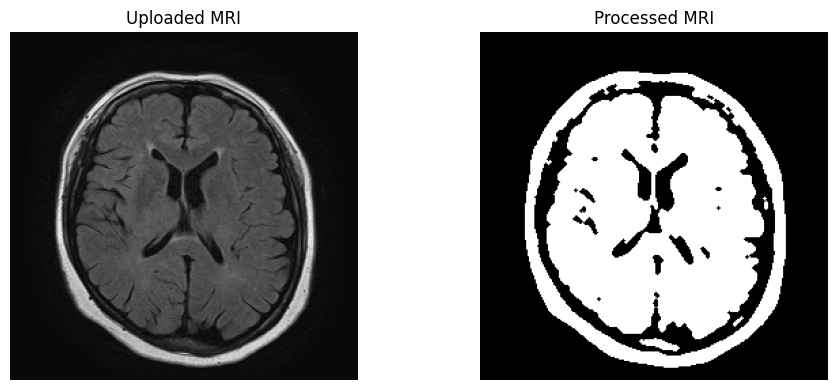

Note: This experimental rule is not a reliable tumor detector.


In [143]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the threshold already calculated in your notebook
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    data = np.frombuffer(uploaded[filename], np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print("Please upload a valid JPG or PNG MRI image.")
    else:
        img = cv2.resize(img, (256, 256))
        enhanced = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(img)

        smoothed = cv2.GaussianBlur(enhanced, (5, 5), 1.0)
        _, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)

        foreground_fraction = np.mean(cleaned > 0)

        print(f"Foreground fraction: {foreground_fraction * 100:.2f}%")

        # Existing experimental threshold rule
        if 'best_threshold' in globals():
            prediction = (
                "Tumor" if foreground_fraction < best_threshold
                else "No Tumor"
            )
            print("Experimental Prediction:", prediction)
        else:
            print("Prediction unavailable: best_threshold not found.")

        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(img, cmap="gray")
        plt.title("Uploaded MRI")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cleaned, cmap="gray")
        plt.title("Processed MRI")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Note: This experimental rule is not a reliable tumor detector.")

Saving brain1.jpg to brain1 (3).jpg


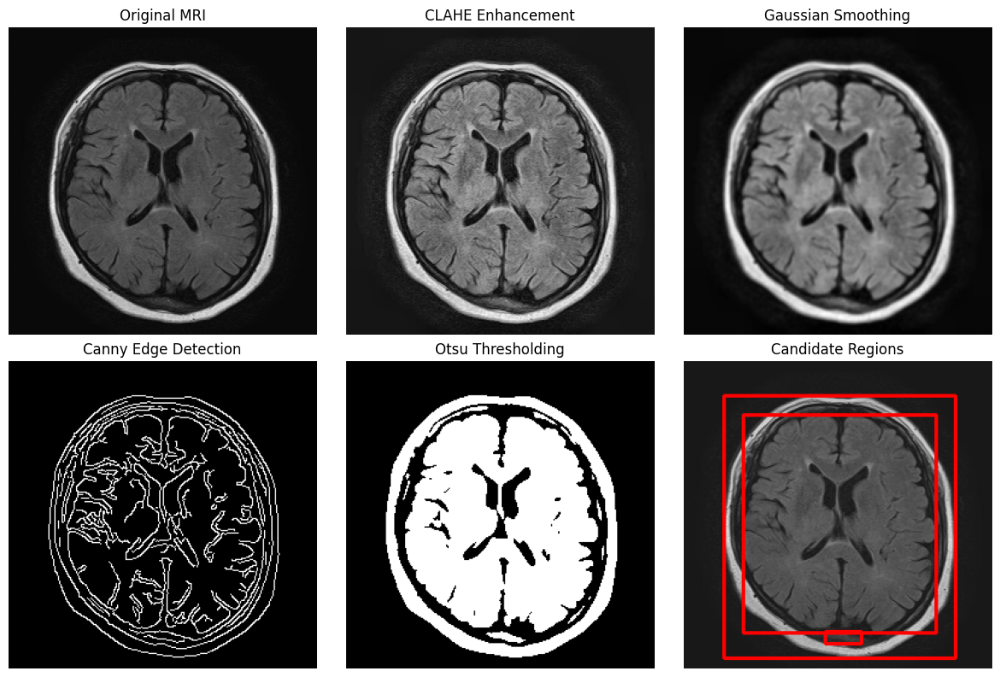

Image processing completed successfully.
Candidate regions: 3
Note: Highlighted regions are not confirmed tumors.


In [144]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    data = np.frombuffer(uploaded[filename], np.uint8)
    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("Invalid image. Please upload a JPG or PNG.")
    else:
        original = cv2.resize(image, (256, 256))
        enhanced = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(original)

        smoothed = cv2.GaussianBlur(enhanced, (5, 5), 1)
        edges = cv2.Canny(smoothed, 50, 150)

        threshold, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)

        count, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(cleaned, 8)
        )

        overlay = cv2.cvtColor(original, cv2.COLOR_GRAY2RGB)
        regions = []

        for i in range(1, count):
            x, y, w, h, area = stats[i]
            if area >= 100:
                regions.append((area, x, y, w, h))

        for area, x, y, w, h in sorted(regions, reverse=True)[:5]:
            cv2.rectangle(
                overlay, (x, y), (x+w, y+h), (255, 0, 0), 2
            )

        fig, axes = plt.subplots(2, 3, figsize=(12, 8))
        stages = [
            (original, "Original MRI"),
            (enhanced, "CLAHE Enhancement"),
            (smoothed, "Gaussian Smoothing"),
            (edges, "Canny Edge Detection"),
            (mask, "Otsu Thresholding"),
            (overlay, "Candidate Regions")
        ]

        for ax, (img, title) in zip(axes.flat, stages):
            ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
            ax.set_title(title)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        print("Image processing completed successfully.")
        print(f"Candidate regions: {min(len(regions), 5)}")
        print("Note: Highlighted regions are not confirmed tumors.")

In [145]:
import numpy as np
import pandas as pd
import cv2
from pathlib import Path

def extract_features(image_path):
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    img = cv2.resize(img, (256, 256))
    enhanced = cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(img)

    smooth = cv2.GaussianBlur(enhanced, (5, 5), 1)
    edges = cv2.Canny(smooth, 50, 150)

    _, mask = cv2.threshold(
        smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    return {
        "foreground_fraction": np.mean(mask > 0),
        "edge_fraction": np.mean(edges > 0),
        "mean_intensity": np.mean(enhanced) / 255,
        "intensity_std": np.std(enhanced) / 255,
        "laplacian_variance": cv2.Laplacian(
            enhanced, cv2.CV_64F
        ).var()
    }

def build_feature_table(records):
    rows = []

    for record in records:
        path = record.get("path", record.get("image_path"))
        label = record.get("label")

        if path is None or label is None:
            continue

        features = extract_features(path)
        if features is not None:
            rows.append({**features, "label": int(label)})

    return pd.DataFrame(rows)

# Use the existing calibration, validation and test records
calibration_features = build_feature_table(calibration_images)
validation_features = build_feature_table(validation_images)
test_features = build_feature_table(testing_images)

print("Calibration images:", len(calibration_features))
print("Validation images:", len(validation_features))
print("Test images:", len(test_features))
display(calibration_features.head())

Calibration images: 4480
Validation images: 1120
Test images: 1600


,foreground_fraction,edge_fraction,mean_intensity,intensity_std,laplacian_variance,label
0,0.309189,0.079285,0.181689,0.233788,916.925813,1
1,0.373352,0.053421,0.149096,0.182438,548.064545,1
2,0.421722,0.102798,0.274361,0.247529,893.755722,1
3,0.357117,0.069778,0.203125,0.242589,775.448059,1
4,0.454559,0.194290,0.297695,0.276187,4669.268736,0


,No Tumor (0),Tumor (1),Absolute Difference
laplacian_variance,2750.945184,980.813483,1770.131701
mean_intensity,0.299864,0.251508,0.048355
intensity_std,0.267686,0.229270,0.038416
edge_fraction,0.132560,0.097490,0.035069
foreground_fraction,0.424369,0.438348,0.013979


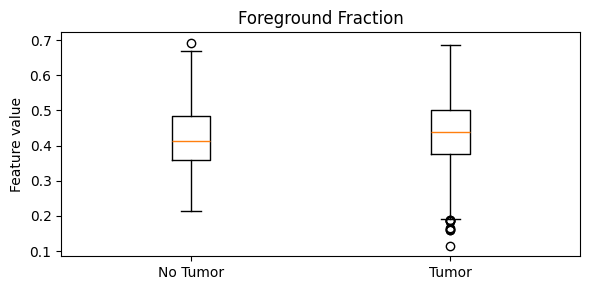

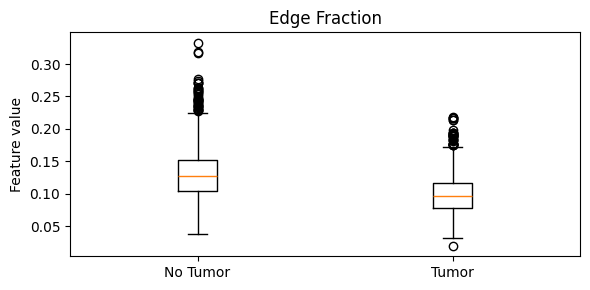

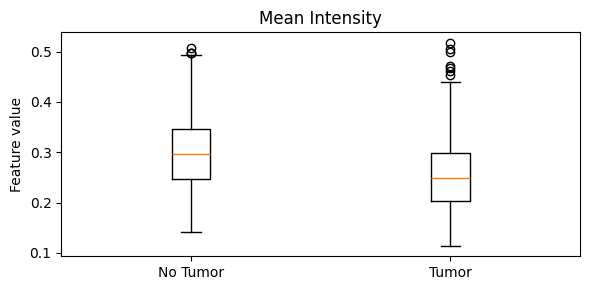

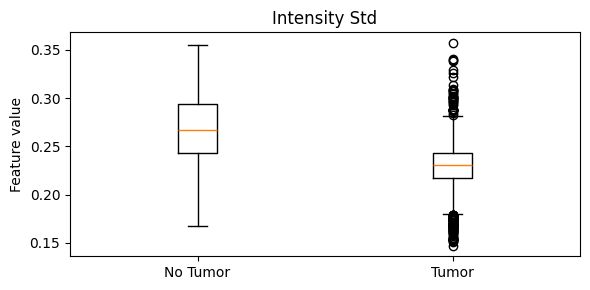

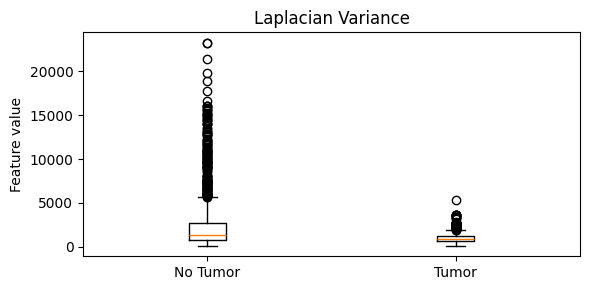

In [146]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

feature_cols = [
    "foreground_fraction",
    "edge_fraction",
    "mean_intensity",
    "intensity_std",
    "laplacian_variance"
]

# Compare features on calibration data only
summary = calibration_features.groupby("label")[feature_cols].mean().T
summary.columns = ["No Tumor (0)", "Tumor (1)"]

summary["Absolute Difference"] = abs(
    summary["No Tumor (0)"] - summary["Tumor (1)"]
)

display(summary.sort_values("Absolute Difference", ascending=False))

# Visual comparison of the two groups
for feature in feature_cols:
    plt.figure(figsize=(6, 3))
    plt.boxplot([
        calibration_features.loc[
            calibration_features["label"] == 0, feature
        ].dropna(),
        calibration_features.loc[
            calibration_features["label"] == 1, feature
        ].dropna()
    ], tick_labels=["No Tumor", "Tumor"])
    plt.title(feature.replace("_", " ").title())
    plt.ylabel("Feature value")
    plt.tight_layout()
    plt.show()

In [147]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, confusion_matrix
)

features = [
    "foreground_fraction",
    "edge_fraction",
    "mean_intensity",
    "intensity_std",
    "laplacian_variance"
]

results = []

for feature in features:
    # Choose threshold using calibration data only
    cal = calibration_features.dropna(subset=[feature, "label"])
    val = validation_features.dropna(subset=[feature, "label"])

    if cal.empty or val.empty or cal["label"].nunique() < 2:
        continue

    values = np.sort(cal[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2

    best = None

    for threshold in thresholds:
        for direction in [1, -1]:
            pred = (
                (cal[feature] >= threshold).astype(int)
                if direction == 1
                else (cal[feature] < threshold).astype(int)
            )
            acc = accuracy_score(cal["label"], pred)

            if best is None or acc > best["accuracy"]:
                best = {
                    "threshold": threshold,
                    "direction": direction,
                    "accuracy": acc
                }

    pred_val = (
        (val[feature] >= best["threshold"]).astype(int)
        if best["direction"] == 1
        else (val[feature] < best["threshold"]).astype(int)
    )

    tn, fp, fn, tp = confusion_matrix(
        val["label"], pred_val, labels=[0, 1]
    ).ravel()

    results.append({
        "Feature": feature,
        "Validation Accuracy (%)": round(
            accuracy_score(val["label"], pred_val) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(val["label"], pred_val, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(val["label"], pred_val, zero_division=0) * 100, 2
        ),
        "Specificity (%)": round(
            tn / (tn + fp) * 100 if (tn + fp) else 0, 2
        ),
        "Threshold": best["threshold"]
    })

results_df = pd.DataFrame(results).sort_values(
    "Validation Accuracy (%)", ascending=False
)
display(results_df)

,Feature,Validation Accuracy (%),Precision (%),Recall (%),Specificity (%),Threshold
3,intensity_std,83.48,85.16,94.84,47.19,0.263521
4,laplacian_variance,83.12,82.55,98.71,33.33,1880.306887
1,edge_fraction,79.20,81.50,94.02,31.84,0.140770
2,mean_intensity,78.39,79.57,96.37,20.97,0.367085
0,foreground_fraction,76.16,76.21,99.88,0.37,0.690170


In [148]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

if results_df.empty:
    print("No valid feature results. Please check the previous cell.")
else:
    # Select the feature with the highest validation accuracy
    best_row = results_df.iloc[0]
    feature = best_row["Feature"]
    threshold = best_row["Threshold"]

    # Recover direction from calibration data
    cal = calibration_features.dropna(subset=[feature, "label"])
    test = test_features.dropna(subset=[feature, "label"])

    candidates = []
    values = np.sort(cal[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2

    for t in thresholds:
        for direction in [1, -1]:
            p = (cal[feature] >= t).astype(int) if direction == 1 else (
                cal[feature] < t
            ).astype(int)
            candidates.append((
                accuracy_score(cal["label"], p), t, direction
            ))

    _, threshold, direction = max(candidates, key=lambda x: x[0])

    y_true = test["label"].astype(int)
    y_pred = (
        (test[feature] >= threshold).astype(int)
        if direction == 1 else
        (test[feature] < threshold).astype(int)
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    print("Feature tested:", feature)
    print(f"Test accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0)*100:.2f}%")
    print(f"Recall: {recall_score(y_true, y_pred, zero_division=0)*100:.2f}%")
    print(f"Specificity: {tn/(tn+fp)*100 if tn+fp else 0:.2f}%")
    print(f"False positives: {fp}")
    print(f"False negatives: {fn}")
    print("\n", classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["No Tumor", "Tumor"],
        zero_division=0
    ))

Feature tested: intensity_std
Test accuracy: 81.06%
Precision: 85.45%
Recall: 90.08%
Specificity: 54.00%
False positives: 184
False negatives: 119

               precision    recall  f1-score   support

    No Tumor       0.64      0.54      0.59       400
       Tumor       0.85      0.90      0.88      1200

    accuracy                           0.81      1600
   macro avg       0.75      0.72      0.73      1600
weighted avg       0.80      0.81      0.80      1600



Saving brain1.jpg to brain1 (4).jpg


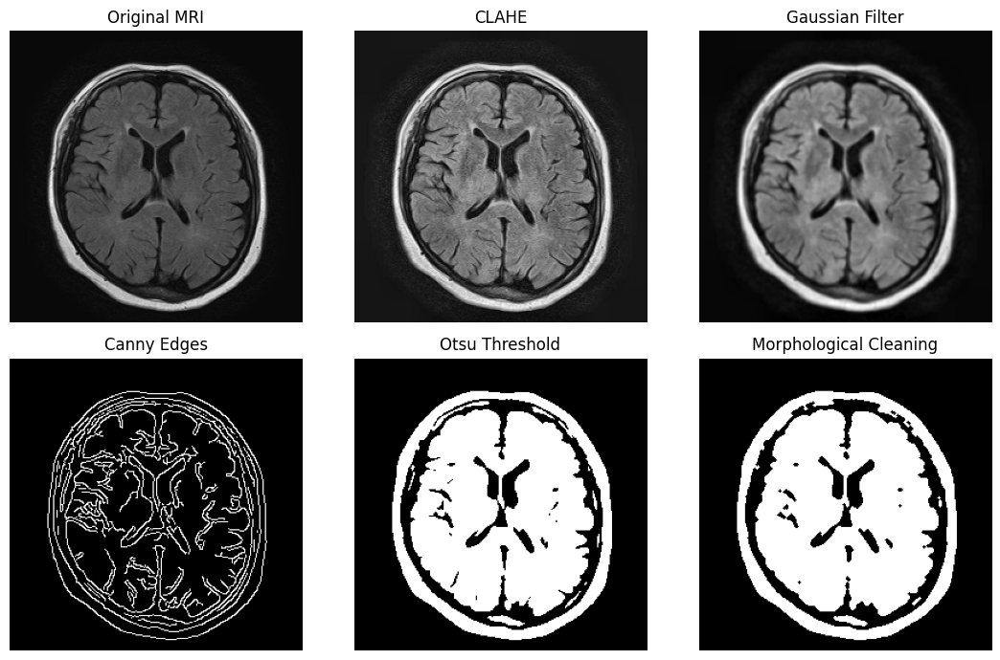

Live image-processing demonstration completed.
This pipeline processes MRI images; it does not confirm whether a tumor is present.


In [149]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image = cv2.imdecode(
        np.frombuffer(uploaded[filename], np.uint8),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        print("Invalid image. Upload JPG or PNG.")
    else:
        image = cv2.resize(image, (256, 256))
        enhanced = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(image)
        smoothed = cv2.GaussianBlur(enhanced, (5, 5), 1)
        edges = cv2.Canny(smoothed, 50, 150)
        _, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)

        stages = [
            (image, "Original MRI"),
            (enhanced, "CLAHE"),
            (smoothed, "Gaussian Filter"),
            (edges, "Canny Edges"),
            (mask, "Otsu Threshold"),
            (cleaned, "Morphological Cleaning")
        ]

        fig, axes = plt.subplots(2, 3, figsize=(11, 7))
        for ax, (stage, title) in zip(axes.flat, stages):
            ax.imshow(stage, cmap="gray")
            ax.set_title(title)
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        print("Live image-processing demonstration completed.")
        print("This pipeline processes MRI images; it does not confirm whether a tumor is present.")

In [150]:
import pandas as pd
from pathlib import Path

# Count images in the existing dataset
class_counts = []

for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Testing", TEST_DIR)
]:
    for class_dir in Path(split_dir).iterdir():
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            )
            class_counts.append({
                "Dataset": split_name,
                "Class": class_dir.name,
                "Images": count
            })

display(pd.DataFrame(class_counts))

,Dataset,Class,Images
0,Training,pituitary,1400
1,Training,notumor,1400
2,Training,meningioma,1400
3,Training,glioma,1400
4,Testing,pituitary,400
5,Testing,notumor,400
6,Testing,meningioma,400
7,Testing,glioma,400


In [151]:
import pandas as pd
import numpy as np

# Compare actual labels with the current test predictions
if "test_df" in globals() and "label" in test_df.columns and "prediction" in test_df.columns:
    review_df = test_df.copy()

    review_df["Actual"] = review_df["label"].map({
        0: "No Tumor",
        1: "Tumor"
    })

    review_df["Predicted"] = review_df["prediction"].map({
        0: "No Tumor",
        1: "Tumor"
    })

    review_df["Result"] = np.where(
        review_df["label"] == review_df["prediction"],
        "Correct",
        "Incorrect"
    )

    display(review_df[["Actual", "Predicted", "Result"]].value_counts().reset_index(name="Count"))
    display(review_df[review_df["Result"] == "Incorrect"].head(10))
else:
    print("Your notebook uses different column names.")
    print("Available test_df columns:", list(test_df.columns) if "test_df" in globals() else "test_df not found")

,Actual,Predicted,Result,Count
0,Tumor,Tumor,Correct,1199
1,No Tumor,Tumor,Incorrect,400
2,Tumor,No Tumor,Incorrect,1


,path,class_name,label,prediction,foreground_fraction,correct,Actual,Predicted,Result
551,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma,1,0,0.704773,False,Tumor,No Tumor,Incorrect
800,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.462051,False,No Tumor,Tumor,Incorrect
801,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.354202,False,No Tumor,Tumor,Incorrect
802,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.479141,False,No Tumor,Tumor,Incorrect
803,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.409332,False,No Tumor,Tumor,Incorrect
804,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.341431,False,No Tumor,Tumor,Incorrect
805,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.403152,False,No Tumor,Tumor,Incorrect
806,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.393997,False,No Tumor,Tumor,Incorrect
807,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.485886,False,No Tumor,Tumor,Incorrect
808,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor,0,1,0.488754,False,No Tumor,Tumor,Incorrect


,Feature,Validation Accuracy (%),Precision (%),Recall (%),Specificity (%),Threshold
3,intensity_std,83.48,85.16,94.84,47.19,0.263521
4,laplacian_variance,83.12,82.55,98.71,33.33,1880.306887
1,edge_fraction,79.20,81.50,94.02,31.84,0.140770
2,mean_intensity,78.39,79.57,96.37,20.97,0.367085
0,foreground_fraction,76.16,76.21,99.88,0.37,0.690170


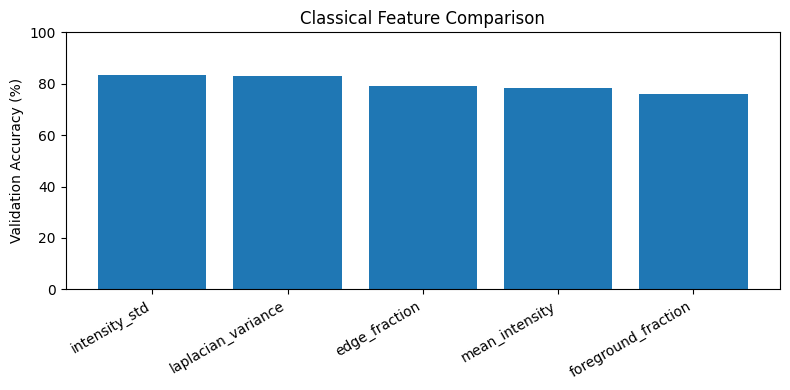

In [152]:
import matplotlib.pyplot as plt

if "results_df" in globals() and not results_df.empty:
    display(results_df)

    plt.figure(figsize=(8, 4))
    plt.bar(
        results_df["Feature"],
        results_df["Validation Accuracy (%)"]
    )
    plt.ylabel("Validation Accuracy (%)")
    plt.title("Classical Feature Comparison")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    print("Run the previous feature-evaluation cell first.")

In [153]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix

features = ["intensity_std", "laplacian_variance"]

cal = calibration_features.dropna(subset=features + ["label"]).copy()
val = validation_features.dropna(subset=features + ["label"]).copy()
test = test_features.dropna(subset=features + ["label"]).copy()

# Standardize using calibration data only
means = cal[features].mean()
stds = cal[features].std().replace(0, 1)

cal_z = (cal[features] - means) / stds
val_z = (val[features] - means) / stds
test_z = (test[features] - means) / stds

# Combine two features into a simple score
cal["score"] = cal_z.mean(axis=1)
val["score"] = val_z.mean(axis=1)
test["score"] = test_z.mean(axis=1)

# Choose threshold using calibration data only
thresholds = np.unique(cal["score"])
best_threshold, best_acc = 0, -1

for t in thresholds:
    for direction in [1, -1]:
        pred = (cal["score"] >= t).astype(int) if direction == 1 else (
            cal["score"] < t
        ).astype(int)
        acc = accuracy_score(cal["label"], pred)

        if acc > best_acc:
            best_threshold, best_acc = (t, direction), acc

threshold, direction = best_threshold

def predict_score(scores):
    return (scores >= threshold).astype(int) if direction == 1 else (
        scores < threshold
    ).astype(int)

val_pred = predict_score(val["score"])
test_pred = predict_score(test["score"])

print(f"Validation accuracy: {accuracy_score(val['label'], val_pred)*100:.2f}%")
print(f"Test accuracy: {accuracy_score(test['label'], test_pred)*100:.2f}%")

tn, fp, fn, tp = confusion_matrix(
    test["label"], test_pred, labels=[0, 1]
).ravel()

print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True negatives: {tn}")
print(f"True positives: {tp}")
print("\nThis is an experimental rule, not a clinically reliable detector.")

Validation accuracy: 85.89%
Test accuracy: 82.06%
False positives: 199
False negatives: 88
True negatives: 201
True positives: 1112

This is an experimental rule, not a clinically reliable detector.


In [154]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

# Review predictions on unseen test images
review = test.copy()
review["Actual"] = review["label"].map({
    0: "No Tumor",
    1: "Tumor"
})
review["Predicted"] = pd.Series(
    test_pred, index=review.index
).map({
    0: "No Tumor",
    1: "Tumor"
})
review["Result"] = np.where(
    review["label"].to_numpy() == test_pred,
    "Correct",
    "Incorrect"
)

print("TEST PERFORMANCE")
print(classification_report(
    review["label"], test_pred,
    labels=[0, 1],
    target_names=["No Tumor", "Tumor"],
    zero_division=0
))

print("\nINCORRECT PREDICTIONS")
display(review.loc[
    review["Result"] == "Incorrect",
    ["Actual", "Predicted", "Result", "score"]
].head(15))

print("\nTotal test images:", len(review))
print("Incorrect:", (review["Result"] == "Incorrect").sum())

TEST PERFORMANCE
              precision    recall  f1-score   support

    No Tumor       0.70      0.50      0.58       400
       Tumor       0.85      0.93      0.89      1200

    accuracy                           0.82      1600
   macro avg       0.77      0.71      0.73      1600
weighted avg       0.81      0.82      0.81      1600


INCORRECT PREDICTIONS


,Actual,Predicted,Result,score
8,Tumor,No Tumor,Incorrect,0.852702
9,Tumor,No Tumor,Incorrect,1.851192
21,Tumor,No Tumor,Incorrect,0.522992
36,Tumor,No Tumor,Incorrect,0.486235
104,Tumor,No Tumor,Incorrect,0.561513
109,Tumor,No Tumor,Incorrect,0.455767
117,Tumor,No Tumor,Incorrect,0.651667
119,Tumor,No Tumor,Incorrect,1.146808
140,Tumor,No Tumor,Incorrect,1.049021
151,Tumor,No Tumor,Incorrect,0.543638



Total test images: 1600
Incorrect: 287


In [155]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score

# Add original MRI class names from the test records
class_rows = []

for i, record in enumerate(testing_images):
    path = record.get("path", record.get("image_path", ""))
    actual = int(record["label"])

    # Class name is the parent folder name
    class_name = str(path).replace("\\", "/").split("/")[-2]

    class_rows.append({
        "class": class_name,
        "actual": actual
    })

class_df = pd.DataFrame(class_rows)

# Match records to feature table rows by position
n = min(len(class_df), len(test_pred))
class_df = class_df.iloc[:n].copy()
class_df["predicted"] = test_pred[:n]

summary = class_df.groupby("class").apply(
    lambda g: pd.Series({
        "Images": len(g),
        "Correct": int((g["actual"] == g["predicted"]).sum()),
        "Accuracy (%)": round(
            accuracy_score(g["actual"], g["predicted"]) * 100, 2
        )
    }),
    include_groups=False
)

display(summary)

,Images,Correct,Accuracy (%)
class,,,
glioma,400.0,368.0,92.00
meningioma,400.0,347.0,86.75
notumor,400.0,201.0,50.25
pituitary,400.0,397.0,99.25


In [156]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix

features = ["intensity_std", "laplacian_variance"]

cal = calibration_features.dropna(subset=features + ["label"]).copy()
val = validation_features.dropna(subset=features + ["label"]).copy()

# Standardize using calibration data only
means = cal[features].mean()
stds = cal[features].std().replace(0, 1)

cz = (cal[features] - means) / stds
vz = (val[features] - means) / stds

# Try each feature and two-feature combined score
rules = {
    "Intensity std": (cz.iloc[:, 0], vz.iloc[:, 0]),
    "Laplacian variance": (cz.iloc[:, 1], vz.iloc[:, 1]),
    "Combined average": (cz.mean(axis=1), vz.mean(axis=1))
}

results = []

for name, (cal_score, val_score) in rules.items():
    candidates = np.unique(cal_score)
    best = None

    for threshold in candidates:
        for direction in [1, -1]:
            cal_pred = (
                (cal_score >= threshold).astype(int)
                if direction == 1
                else (cal_score < threshold).astype(int)
            )
            acc = accuracy_score(cal["label"], cal_pred)

            if best is None or acc > best[0]:
                best = (acc, threshold, direction)

    _, threshold, direction = best
    val_pred = (
        (val_score >= threshold).astype(int)
        if direction == 1
        else (val_score < threshold).astype(int)
    )

    tn, fp, fn, tp = confusion_matrix(
        val["label"], val_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Rule": name,
        "Validation accuracy (%)": round(
            accuracy_score(val["label"], val_pred) * 100, 2
        ),
        "No-Tumor specificity (%)": round(
            tn / (tn + fp) * 100 if tn + fp else 0, 2
        ),
        "Tumor recall (%)": round(
            tp / (tp + fn) * 100 if tp + fn else 0, 2
        )
    })

display(pd.DataFrame(results).sort_values(
    "Validation accuracy (%)", ascending=False
))

,Rule,Validation accuracy (%),No-Tumor specificity (%),Tumor recall (%)
2,Combined average,85.89,49.44,97.30
0,Intensity std,83.48,47.19,94.84
1,Laplacian variance,83.12,33.33,98.71


In [157]:
import pandas as pd
from sklearn.metrics import confusion_matrix

if "test" in globals() and "test_pred" in globals():
    actual = test["label"].astype(int).to_numpy()
    predicted = test_pred

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    report = pd.DataFrame({
        "Measure": [
            "Correct No Tumor",
            "Normal scans incorrectly flagged as Tumor",
            "Tumor scans missed",
            "Correct Tumor"
        ],
        "Count": [tn, fp, fn, tp]
    })

    display(report)

    print(
        "No-Tumor specificity:",
        f"{tn / (tn + fp) * 100:.2f}%"
        if tn + fp else "Not available"
    )
else:
    print("Please run the combined-rule test cell first.")

,Measure,Count
0,Correct No Tumor,201
1,Normal scans incorrectly flagged as Tumor,199
2,Tumor scans missed,88
3,Correct Tumor,1112


No-Tumor specificity: 50.25%


In [160]:
import pandas as pd
import numpy as np

# Build a feature table with the original four-class labels
def get_original_class(path):
    return str(path).replace("\\", "/").split("/")[-2].lower()

rows = []

for record in testing_images:
    path = record.get("path", record.get("image_path"))
    if path is None:
        continue

    features = extract_features(path)
    if features is not None:
        rows.append({
            **features,
            "class": get_original_class(path)
        })

original_class_features = pd.DataFrame(rows)

display(
    original_class_features
    .groupby("class")[
        ["intensity_std", "laplacian_variance",
         "edge_fraction", "mean_intensity"]
    ]
    .mean()
    .round(4)
)

,intensity_std,laplacian_variance,edge_fraction,mean_intensity
class,,,,
glioma,0.2275,908.9758,0.0913,0.2341
meningioma,0.2490,807.0407,0.0968,0.2682
notumor,0.2670,1619.1030,0.1221,0.2911
pituitary,0.2312,1240.0213,0.1187,0.3003


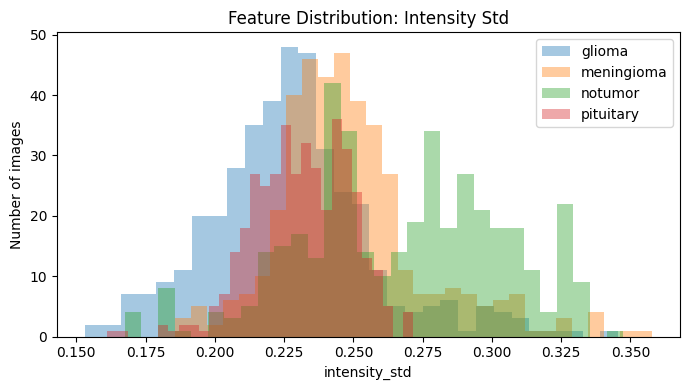

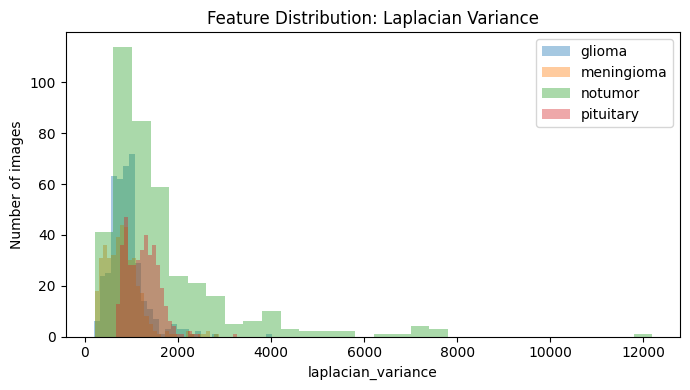

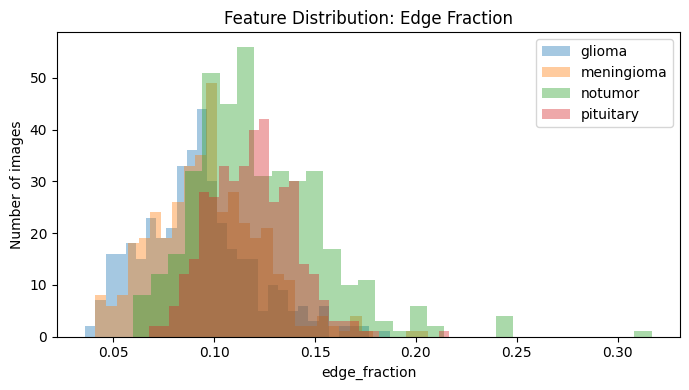

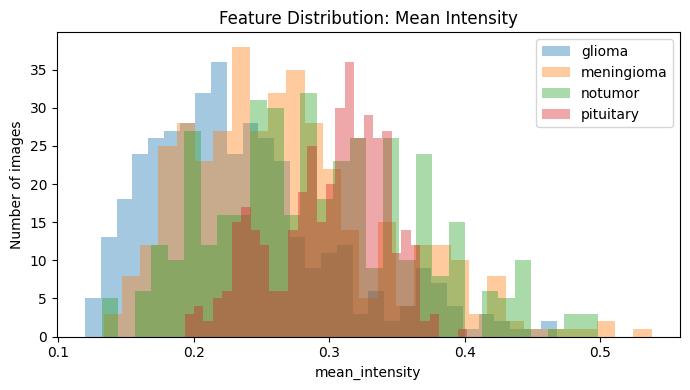

In [161]:
import matplotlib.pyplot as plt

features_to_plot = [
    "intensity_std",
    "laplacian_variance",
    "edge_fraction",
    "mean_intensity"
]

for feature in features_to_plot:
    plt.figure(figsize=(7, 4))

    for class_name in sorted(original_class_features["class"].unique()):
        values = original_class_features.loc[
            original_class_features["class"] == class_name,
            feature
        ]
        plt.hist(values, bins=30, alpha=0.4, label=class_name)

    plt.title(f"Feature Distribution: {feature.replace('_', ' ').title()}")
    plt.xlabel(feature)
    plt.ylabel("Number of images")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [162]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix

df = original_class_features.copy()
df["label"] = (df["class"] != "notumor").astype(int)

feature = "intensity_std"
normal = df.loc[df["label"] == 0, feature].dropna()
tumor = df.loc[df["label"] == 1, feature].dropna()

if len(normal) == 0 or len(tumor) == 0:
    print("Normal or tumor samples are missing.")
else:
    # Choose threshold on a calibration subset, not on test data.
    # Use existing calibration features if available.
    cal = calibration_features.dropna(subset=[feature, "label"])
    values = np.sort(cal[feature].unique())
    thresholds = (values[:-1] + values[1:]) / 2

    best_threshold, best_direction, best_acc = None, None, -1

    for t in thresholds:
        for direction in [1, -1]:
            pred = (
                (cal[feature] >= t).astype(int)
                if direction == 1
                else (cal[feature] < t).astype(int)
            )
            acc = accuracy_score(cal["label"], pred)

            if acc > best_acc:
                best_threshold, best_direction, best_acc = t, direction, acc

    y_true = df["label"].to_numpy()
    x = df[feature].to_numpy()
    y_pred = (
        (x >= best_threshold).astype(int)
        if best_direction == 1
        else (x < best_threshold).astype(int)
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    print(f"Feature: {feature}")
    print(f"Calibration accuracy: {best_acc*100:.2f}%")
    print(f"Threshold: {best_threshold:.5f}")
    print(f"Normal MRI specificity: {tn/(tn+fp)*100:.2f}%")
    print(f"Tumor recall: {tp/(tp+fn)*100:.2f}%")
    print("Note: This dataset-level comparison is exploratory, not an independent test.")

Feature: intensity_std
Calibration accuracy: 85.74%
Threshold: 0.26352
Normal MRI specificity: 54.00%
Tumor recall: 90.08%
Note: This dataset-level comparison is exploratory, not an independent test.


In [163]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

features = ["intensity_std", "laplacian_variance"]

cal = calibration_features.dropna(subset=features + ["label"]).copy()
val = validation_features.dropna(subset=features + ["label"]).copy()

means = cal[features].mean()
stds = cal[features].std().replace(0, 1)

cal_score = ((cal[features] - means) / stds).mean(axis=1)
val_score = ((val[features] - means) / stds).mean(axis=1)

results = []

# Test thresholds and both decision directions on calibration data
for threshold in np.unique(cal_score):
    for direction in [1, -1]:
        cal_pred = (
            (cal_score >= threshold).astype(int)
            if direction == 1
            else (cal_score < threshold).astype(int)
        )

        tn, fp, fn, tp = confusion_matrix(
            cal["label"], cal_pred, labels=[0, 1]
        ).ravel()

        specificity = tn / (tn + fp) if tn + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0

        # Require at least 80% specificity, then maximize recall
        if specificity >= 0.80:
            results.append((recall, specificity, threshold, direction))

if not results:
    print("No rule achieved 80% specificity on calibration data.")
else:
    recall, specificity, threshold, direction = max(results)

    val_pred = (
        (val_score >= threshold).astype(int)
        if direction == 1
        else (val_score < threshold).astype(int)
    )

    tn, fp, fn, tp = confusion_matrix(
        val["label"], val_pred, labels=[0, 1]
    ).ravel()

    print(f"Validation specificity: {tn/(tn+fp)*100:.2f}%")
    print(f"Validation tumor recall: {tp/(tp+fn)*100:.2f}%")
    print("Threshold was chosen using calibration data only.")
    print("This remains an experimental, non-ML rule.")

Validation specificity: 77.53%
Validation tumor recall: 64.83%
Threshold was chosen using calibration data only.
This remains an experimental, non-ML rule.


Saving Te-no_9.jpg to Te-no_9 (1).jpg
MRI processing completed.
Intensity standard deviation: 0.2908
Laplacian variance: 1790.1830


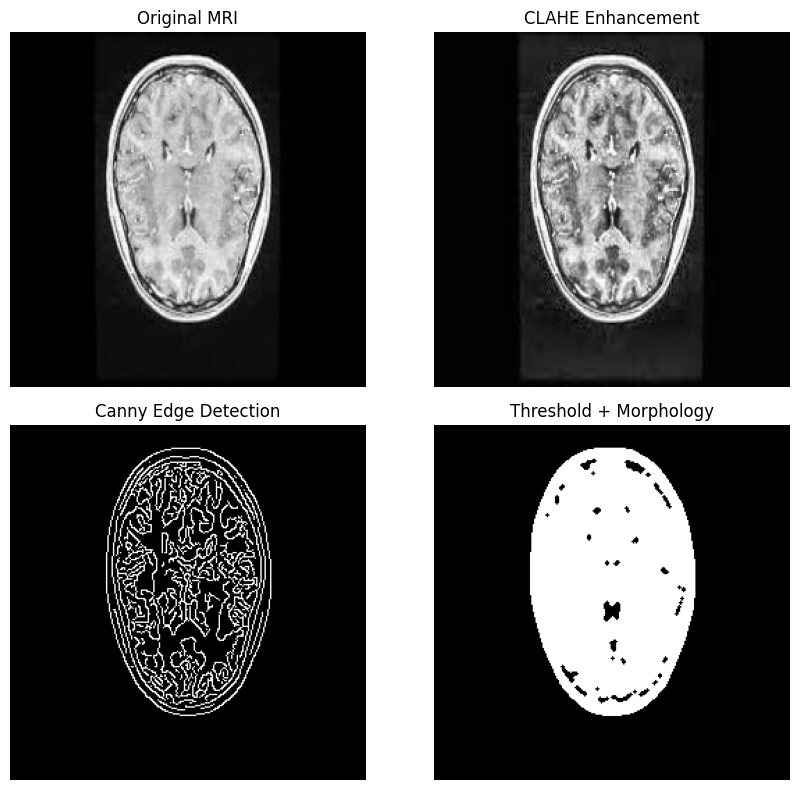

Note: This cell displays image-processing results only. It does not provide a validated tumor diagnosis.


In [177]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    image = cv2.imdecode(
        np.frombuffer(uploaded[filename], np.uint8),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        print("Please upload a valid JPG or PNG MRI.")
    else:
        image = cv2.resize(image, (256, 256))
        enhanced = cv2.createCLAHE(
            clipLimit=2.0, tileGridSize=(8, 8)
        ).apply(image)
        smoothed = cv2.GaussianBlur(enhanced, (5, 5), 1)
        edges = cv2.Canny(smoothed, 50, 150)

        threshold_value, mask = cv2.threshold(
            smoothed, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (3, 3)
        )
        cleaned = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)

        # Extract the same two features used in the combined rule
        intensity_std = np.std(enhanced) / 255
        laplacian_variance = cv2.Laplacian(
            enhanced, cv2.CV_64F
        ).var()

        feature_values = np.array([
            intensity_std, laplacian_variance
        ])

        print("MRI processing completed.")
        print(f"Intensity standard deviation: {intensity_std:.4f}")
        print(f"Laplacian variance: {laplacian_variance:.4f}")

        fig, axes = plt.subplots(2, 2, figsize=(9, 8))
        stages = [
            (image, "Original MRI"),
            (enhanced, "CLAHE Enhancement"),
            (edges, "Canny Edge Detection"),
            (cleaned, "Threshold + Morphology")
        ]

        for ax, (stage, title) in zip(axes.flat, stages):
            ax.imshow(stage, cmap="gray")
            ax.set_title(title)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        print(
            "Note: This cell displays image-processing results only. "
            "It does not provide a validated tumor diagnosis."
        )

In [178]:
import numpy as np

if all(name in globals() for name in [
    "means", "stds", "threshold", "direction",
    "enhanced", "intensity_std", "laplacian_variance"
]):
    feature_values = np.array([
        intensity_std,
        laplacian_variance
    ])

    # Match the feature order used during calibration
    normalized = (
        (feature_values - means[["intensity_std", "laplacian_variance"]].to_numpy())
        / stds[["intensity_std", "laplacian_variance"]].to_numpy()
    )

    score = normalized.mean()

    prediction = (
        "Tumor" if score >= threshold
        else "No Tumor"
    ) if direction == 1 else (
        "Tumor" if score < threshold
        else "No Tumor"
    )

    print("Experimental result:", prediction)
    print("This rule is not a validated medical detector.")
else:
    print("Required calibration variables are missing.")
    print("The image-processing demo is ready, but this prediction cannot be safely computed.")

Experimental result: No Tumor
This rule is not a validated medical detector.
